In [1]:
knitr::opts_chunk$set(echo = TRUE, warning = FALSE, message = FALSE)

In [2]:
# install.packages("gtable", force = TRUE)

In [3]:
# R.version

In [4]:
library(ggplot2)
library(gtable)

Warning message:
“package ‘ggplot2’ was built under R version 4.3.3”


In [5]:
# install.packages("BiocManager")
# BiocManager::install(c("AnnotationDbi", "topGO", "org.Hs.eg.db", "limma", "DESeq2"))

In [6]:
# install.packages("reshape2")
# install.packages("ggpubr")
# install.packages("AnnotationDbi")
# install.packages("topGO")
# install.packages("org.Hs.eg.db")
# install.packages("limma")
# install.packages("DESeq2")
# install.packages("pheatmap")

In [7]:
library(ggplot2)
library(tidyverse)
library(dplyr)
library(reshape2)
library(stringr)
library(ggpubr)
library(readxl)
library(AnnotationDbi)
library(topGO)
library(limma)
library(DESeq2)
library(pheatmap)
library(org.Mm.eg.db)
library(ggrepel)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.4
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ lubridate 1.9.3     ✔ tibble    3.2.1
✔ purrr     1.0.2     ✔ tidyr     1.3.2
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘reshape2’


The following object is masked from ‘package:tidyr’:

    smiths


Warning message:
“package ‘AnnotationDbi’ was built under R version 4.3.2”
Loading required package: stats4

Loading required package: BiocGenerics

Warning message:
“package ‘BiocGenerics’ was built under R version 4.3.2”

Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:lubridate’:

    intersect, setdiff, union


The following objects are masked from ‘package:

# Overview

The dataset encompasses two cell states - Healthy and Glioma cells - subjected to a diverse set of treatments (control, DMSO, 6 drugs) - each analysed in triplicates.

# 1. Load the counts table

Load the data. Note: the data has been subjected to prior inspection, cleaning and curation in a Jupyter Notebook. 

Count data is the raw file extracted from canonical bulk RNAseq. The count data shows the raw number of reads of each sample mapped onto a gene. 

In [8]:
countsLOG_in <- as.data.frame(read_csv("Log2_normalized_countData.csv"))
countsRAW_in <- as.data.frame(read_csv("Raw_countData.csv"))
countsTPM_in <- as.data.frame(read_csv("TPM_normalized_countData.csv"))

# Example: TPM data
head(countsTPM_in)

New names:
• `` -> `...1`
Rows: 15795 Columns: 16
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (1): ...1
dbl (15): Control-1, Control-2, Control-3, DMSO-1, DMSO-2, DMSO-3, AUF-1, AU...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
New names:
• `` -> `...1`
Rows: 15795 Columns: 16
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (1): ...1
dbl (15): Control-1, Control-2, Control-3, DMSO-1, DMSO-2, DMSO-3, AUF-1, AU...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
New names:
• `` -> `...1`
Rows: 15795 Columns: 16
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (1): ...1
dbl (15): Control-1, Control-2, Control-3, DMSO

,...1,Control-1,Control-2,Control-3,DMSO-1,DMSO-2,DMSO-3,AUF-1,AUF-2,AUF-3,CIS-1,CIS-2,CIS-3,TRANS-1,TRANS-2,TRANS-3
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,Mrpl15,23.727834,20.597722,19.651954,18.5371619,16.349347,16.720441,18.846815,18.012570,18.578911,19.561000,18.03569,16.844286,20.784179,17.214133,19.31769
2,Lypla1,67.935507,64.267728,65.091856,72.3671087,79.038391,83.331604,70.688572,71.606352,65.931833,77.835123,63.59674,66.839533,72.497392,70.497912,71.72241
3,Tcea1,147.511839,141.073067,158.111563,129.0564716,138.144453,121.140461,152.811006,163.156904,161.385272,150.880404,147.36811,155.119813,137.436090,141.192180,148.30851
4,Atp6v1h,57.815721,56.430811,58.614368,59.9392124,58.783511,63.666430,92.160039,91.391268,88.539562,79.587138,76.08869,81.249859,106.970386,81.159632,83.25113
5,4732440D04Rik,1.244551,1.268892,1.543434,0.8423059,2.562722,1.815097,1.987138,2.231171,1.872575,2.557811,2.20283,2.118494,1.019057,1.438704,1.71664
6,Rb1cc1,24.445994,23.544289,24.605570,29.7896395,31.997276,28.623343,34.916936,37.501275,35.486970,31.099903,33.63032,35.417673,35.694014,34.882113,30.03851


In [9]:
# Convert Geneid column to rownames
rownames(countsTPM_in) <- countsTPM_in[,1]
countsTPM <- countsTPM_in[,-1]

rownames(countsLOG_in) <- countsLOG_in[,1]
countsLOG <- countsLOG_in[,-1]

rownames(countsRAW_in) <- countsRAW_in[,1]
countsRAW <- countsRAW_in[,-1]

head(countsTPM)

,Control-1,Control-2,Control-3,DMSO-1,DMSO-2,DMSO-3,AUF-1,AUF-2,AUF-3,CIS-1,CIS-2,CIS-3,TRANS-1,TRANS-2,TRANS-3
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Mrpl15,23.727834,20.597722,19.651954,18.5371619,16.349347,16.720441,18.846815,18.012570,18.578911,19.561000,18.03569,16.844286,20.784179,17.214133,19.31769
Lypla1,67.935507,64.267728,65.091856,72.3671087,79.038391,83.331604,70.688572,71.606352,65.931833,77.835123,63.59674,66.839533,72.497392,70.497912,71.72241
Tcea1,147.511839,141.073067,158.111563,129.0564716,138.144453,121.140461,152.811006,163.156904,161.385272,150.880404,147.36811,155.119813,137.436090,141.192180,148.30851
Atp6v1h,57.815721,56.430811,58.614368,59.9392124,58.783511,63.666430,92.160039,91.391268,88.539562,79.587138,76.08869,81.249859,106.970386,81.159632,83.25113
4732440D04Rik,1.244551,1.268892,1.543434,0.8423059,2.562722,1.815097,1.987138,2.231171,1.872575,2.557811,2.20283,2.118494,1.019057,1.438704,1.71664
Rb1cc1,24.445994,23.544289,24.605570,29.7896395,31.997276,28.623343,34.916936,37.501275,35.486970,31.099903,33.63032,35.417673,35.694014,34.882113,30.03851


#### Load annotation

Allows us to explain the observed differences between samples. It qualitatively identifies the samples with experimental variables (cell state, treatment, replicates...)

Here our conditions of interest are TMZ, AUF, DMSO across HCs and Glioma organoids

In [10]:
anno <- as.data.frame(read.csv('sample_annotation.csv', sep=";"))
rownames(anno) <- c(anno$Sample)
head(anno)

,Sample,Treatment,Replicate
,<chr>,<chr>,<int>
Control-1,Control-1,Control,1
Control-2,Control-2,Control,2
Control-3,Control-3,Control,3
DMSO-1,DMSO-1,DMSO,1
DMSO-2,DMSO-2,DMSO,2
DMSO-3,DMSO-3,DMSO,3


# 2. Inspect the data by PCA

PCA (Principal component analysis) reduces the dimensionality of the dataset to allow for visual inspection. Thereby, we can see the shifts in gene expression between cell types and treatment, for instance.

In PCA, each dot represents a sample plotted against 2 dimensions. The distance between dots represents the difference between their global gene expression profiles. 

PC1 represents the biggest source of variation and PC2 represents the second biggest. 

In bulk RNAseq, you can see samples of HC vs Glioma organoids separating along PC1 or PC2 given respective conditions. 

In [11]:
# Define a function for PCA

pca <- function(x){
  
  tpm_pca <- prcomp(t(as.matrix(x)), center = TRUE, scale = TRUE)
  
  # Get contributions of variance of each PC
  pc1 <- summary(tpm_pca)$importance[2,1]*100
  pc2 <- summary(tpm_pca)$importance[2,2]*100
  
  # Configure dataframe for PC1 and PC2 coordinates for all samples
  pcs_1_2 <- tpm_pca$x[,1:2]
  pcs_1_2_sample <- data.frame(cbind(pcs_1_2, rownames(pcs_1_2)))
  colnames(pcs_1_2_sample) <- c("PC1", "PC2", "Sample")
  
  # Transform coordinates to values that can be calculated with
  pcs_1_2_sample$PC1 <- as.numeric(as.character(pcs_1_2_sample$PC1))
  pcs_1_2_sample$PC2 <- as.numeric(as.character(pcs_1_2_sample$PC2))
  
  # Plot data
  p <- ggplot(pcs_1_2_sample, aes(x = PC1, y = PC2, color = Sample))+
    geom_point()+
    theme_minimal()+
    xlab(paste0("PC1 - ", pc1, " % of variance"))+
    ylab(paste0("PC2 - ", pc2, " % of variance"))+
    theme(legend.position = "right")
  
  return(p)
}

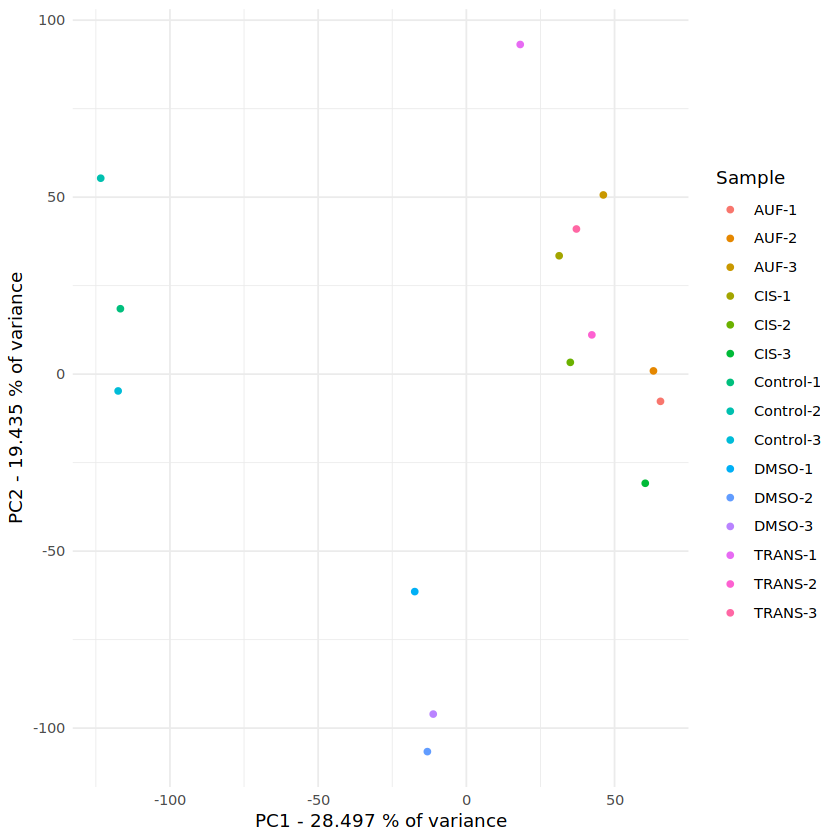

In [12]:
# PCA with all samples, TPM normalised
pca(countsTPM)

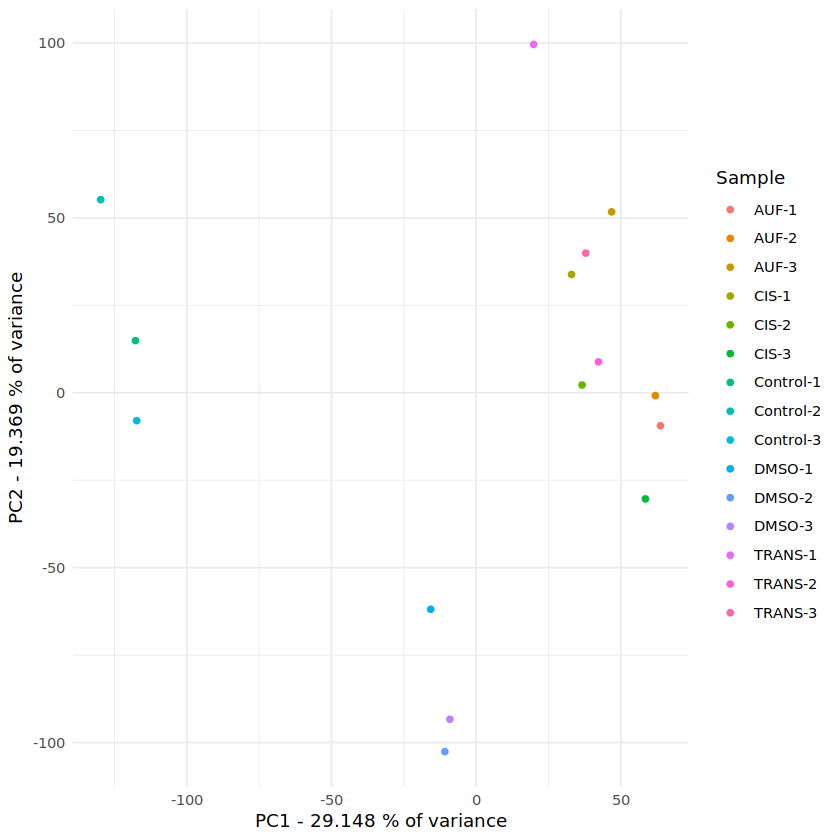

In [13]:
# PCA with all samples, log2 normalized
pca(countsLOG)

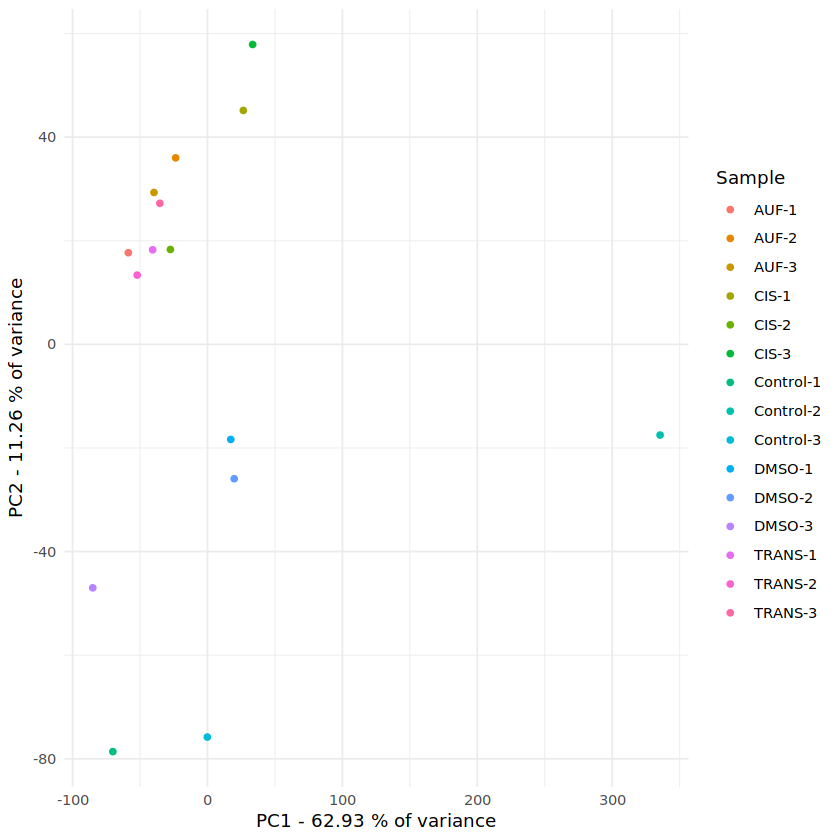

In [14]:
# PCA with all samples, raw counts
pca(countsRAW)

#### PCA with sample annotation

In [15]:
# Define a function for PCA by cell state

pca_by_state <- function(x, anno){
  
  tpm_pca <- prcomp(t(as.matrix(x)), center = TRUE, scale = TRUE)
  
  # Get contributions of variance of each PC
  pc1 <- summary(tpm_pca)$importance[2,1]*100
  pc2 <- summary(tpm_pca)$importance[2,2]*100
  
  # Configure dataframe for PC1 and PC2 coordinates for all samples
  pcs_1_2 <- tpm_pca$x[,1:2]
  sample_info <- anno[rownames(pcs_1_2),c('Treatment', 'Replicate')]
  pcs_1_2_sample <- data.frame(cbind(pcs_1_2, rownames(pcs_1_2), sample_info))
  colnames(pcs_1_2_sample) <- c("PC1", "PC2", "Sample", "Treatment", "Replicate")
  
  # Transform coordinates to values that can be calculated with
  pcs_1_2_sample$PC1 <- as.numeric(as.character(pcs_1_2_sample$PC1))
  pcs_1_2_sample$PC2 <- as.numeric(as.character(pcs_1_2_sample$PC2))
  
  # Plot data
  p <- ggplot(pcs_1_2_sample, aes(x = PC1, y = PC2, color = Treatment))+
    geom_point()+
    theme_minimal()+
    xlab(paste0("PC1 - ", pc1, " % of variance"))+
    ylab(paste0("PC2 - ", pc2, " % of variance"))+
    theme(legend.position = "right")
  
  return(p)
}

Plot PCA with annotation of samples.

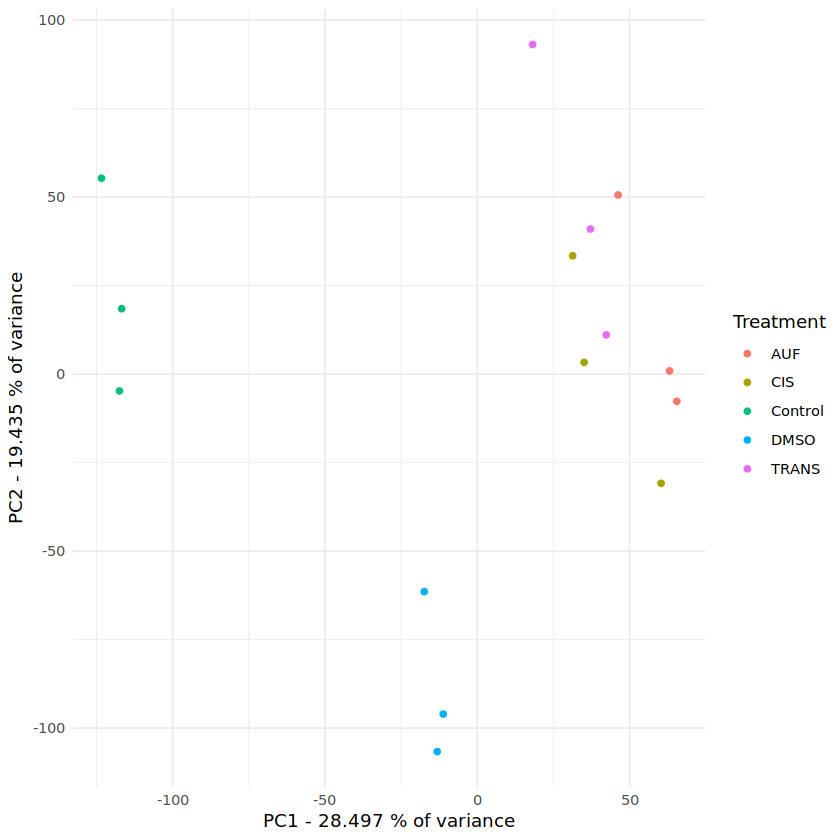

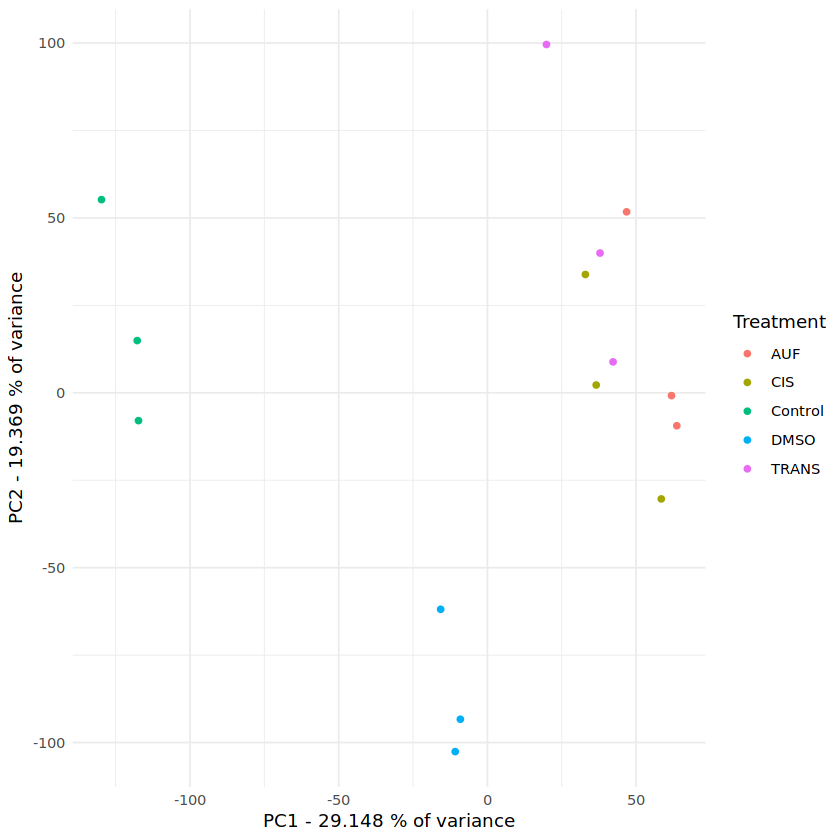

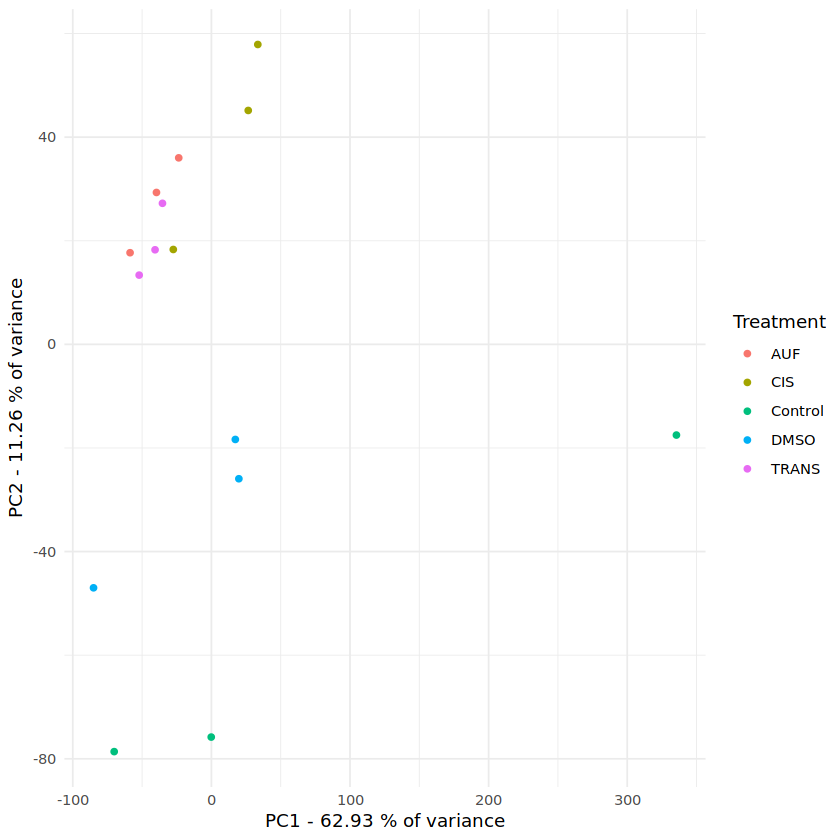

In [16]:
pca_by_state(countsTPM, anno)
pca_by_state(countsLOG, anno)
pca_by_state(countsRAW, anno)

In [17]:
# Define a function for PCA by treatment

pca_by_treatment <- function(x, anno){
  
  tpm_pca <- prcomp(t(as.matrix(x)), center = TRUE, scale = TRUE)
  
  # Get contributions of variance of each PC
  pc1 <- summary(tpm_pca)$importance[2,1]*100
  pc2 <- summary(tpm_pca)$importance[2,2]*100
  
  # Configure dataframe for PC1 and PC2 coordinates for all samples
  pcs_1_2 <- tpm_pca$x[,1:2]
  sample_info <- anno[rownames(pcs_1_2),c('Treatment', 'Replicate')]
  pcs_1_2_sample <- data.frame(cbind(pcs_1_2, rownames(pcs_1_2), sample_info))
  colnames(pcs_1_2_sample) <- c("PC1", "PC2", "Sample", "Treatment", "Replicate")
  
  # Transform coordinates to values that can be calculated with
  pcs_1_2_sample$PC1 <- as.numeric(as.character(pcs_1_2_sample$PC1))
  pcs_1_2_sample$PC2 <- as.numeric(as.character(pcs_1_2_sample$PC2))
  
  # Plot data
  p <- ggplot(pcs_1_2_sample, aes(x = PC1, y = PC2, color = Treatment))+
    geom_point(size=5)+
    theme_minimal()+
    theme(text=element_text(size=15))+
    xlab(paste0("PC1 - ", pc1, " % of variance"))+
    ylab(paste0("PC2 - ", pc2, " % of variance"))+
    theme(legend.position = "right")
  
  return(p)
}

Plot PCA with annotation of samples.

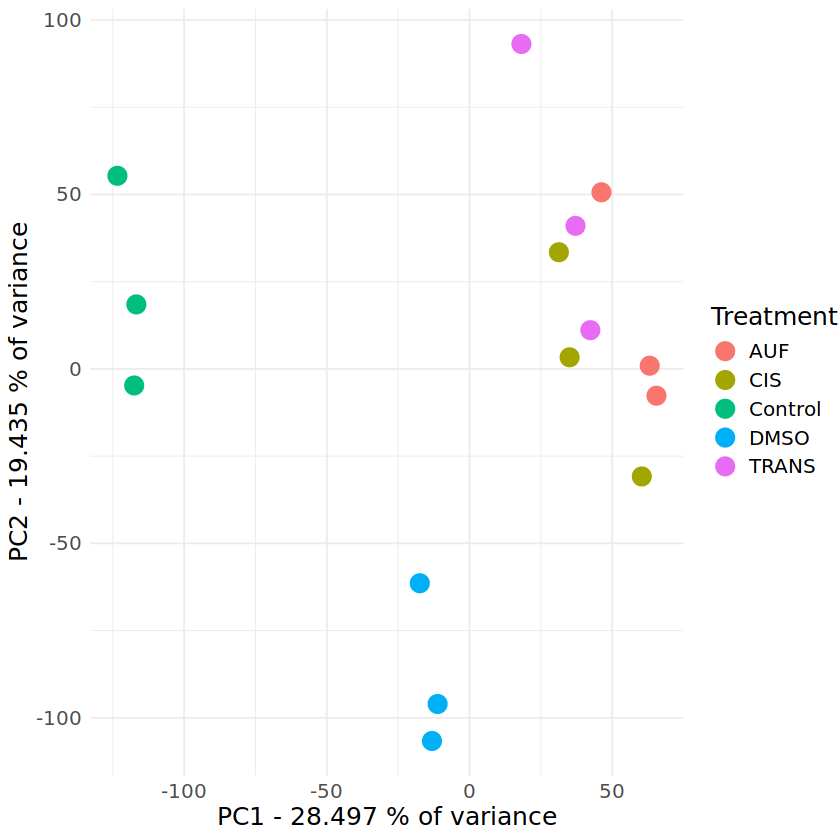

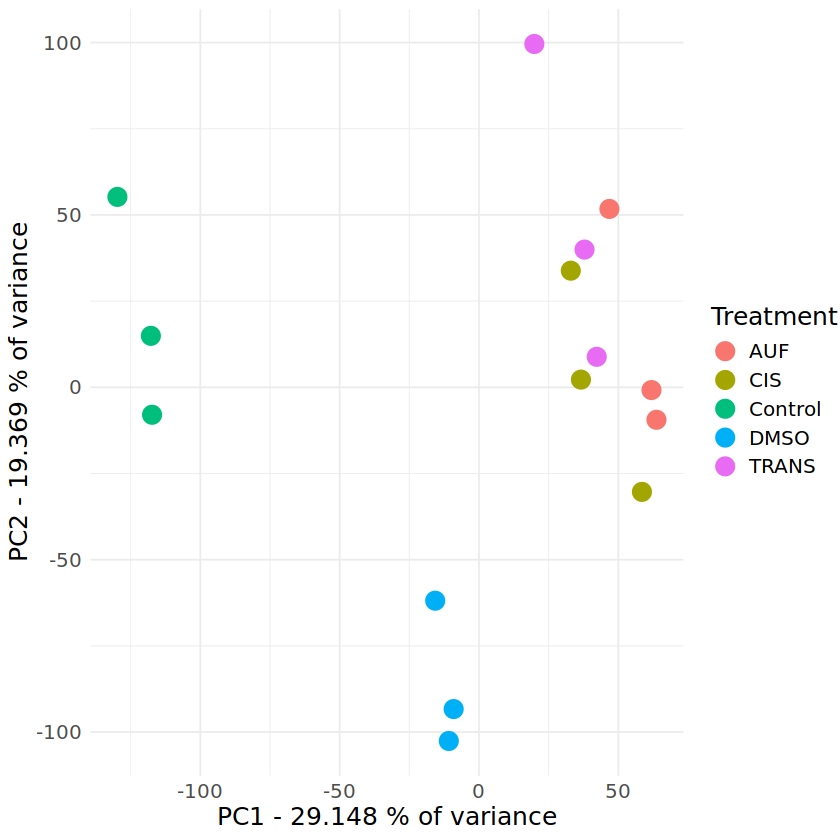

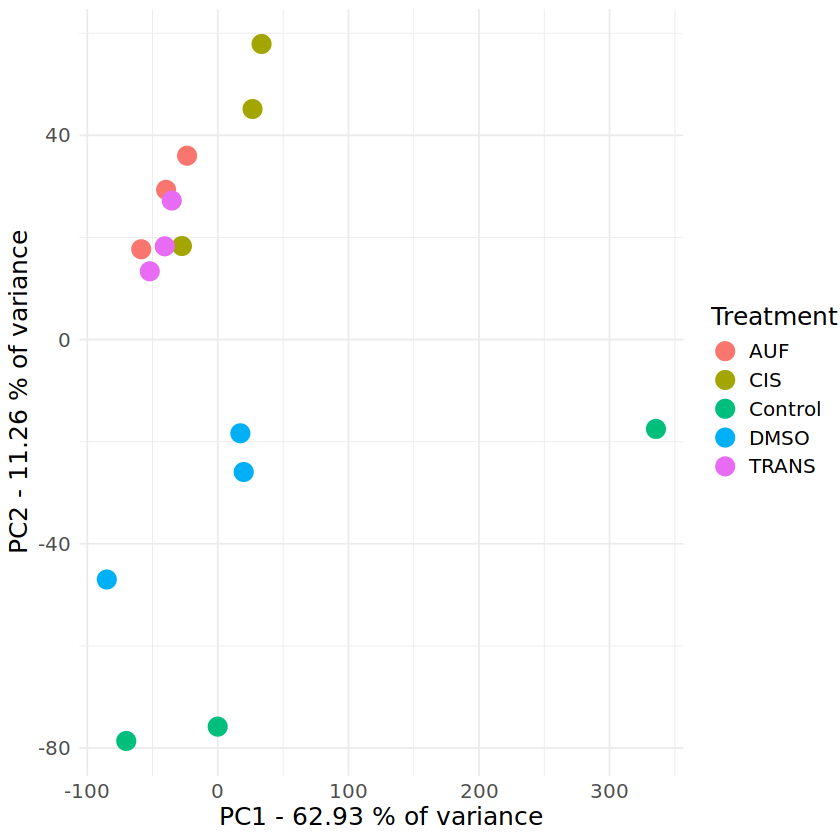

In [18]:
pca_by_treatment(countsTPM, anno)
pca_by_treatment(countsLOG, anno)
pca_by_treatment(countsRAW, anno)

# 3. Compare samples among each other by Pearson's correlation

Pearson's correlations measures the strength of a linear relatioship between 2 variables on a spectrum of -1 to 1. 

1 is a perfect positive relationship, -1 is a perfect negative relationship. 0 is no linear relationship.

Our conditions of interest are TMZ, AUF, and DMSO across HCs and Glioma oragnoids.

,Sample,Treatment
,<chr>,<chr>
Control-1,Control-1,Control
Control-2,Control-2,Control
Control-3,Control-3,Control
DMSO-1,DMSO-1,DMSO
DMSO-2,DMSO-2,DMSO
DMSO-3,DMSO-3,DMSO
AUF-1,AUF-1,AUF
AUF-2,AUF-2,AUF
AUF-3,AUF-3,AUF


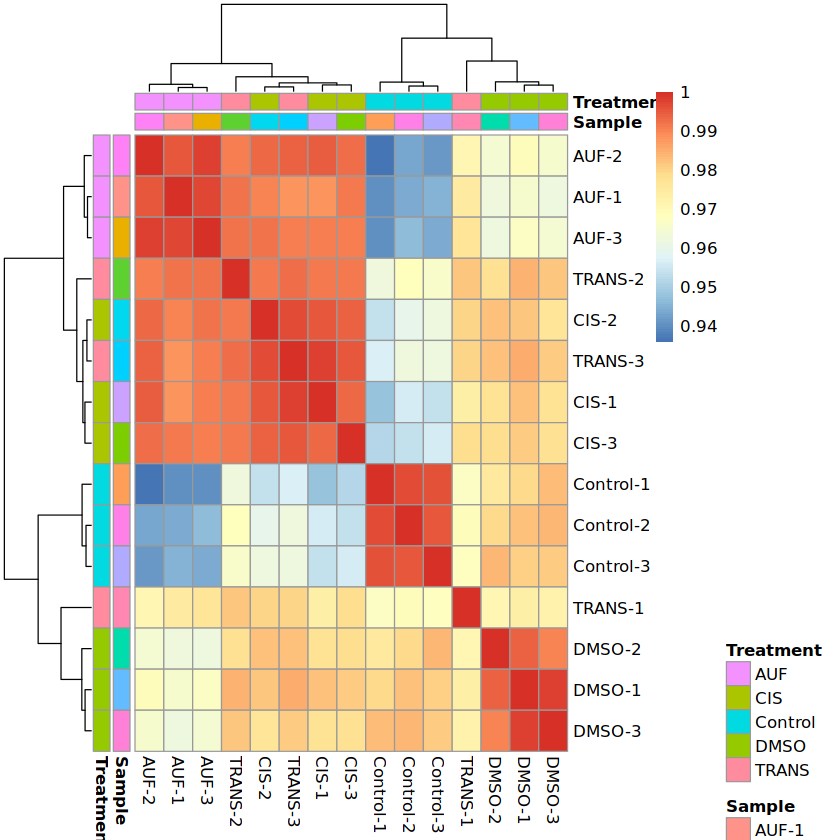

In [19]:
# Pearson Correleation between samples
res <- cor(countsTPM, method = 'pearson')

anno_for_res <- anno[rownames(res), c("Sample", "Treatment")]
anno_for_res

pheatmap(res, annotation_row = anno_for_res, annotation_col = anno_for_res)

# 4. Plot a heatmap

In a heatmap, one can visualize the overall expression of genes. Here, we filter out the 2,000 most variable genes and z-score-normalize each gene that across all samples.

Z score measures the distance of a gene expression value from the mean across samples (std). 

A sample value can 1, 2, or 3 std away from the mean. z > 0 shows a higher-than-average expression. and z < 0 shows lower than average expression for that gene. 

Basically: which samples have higher or lower expression relative to the gene’s mean.

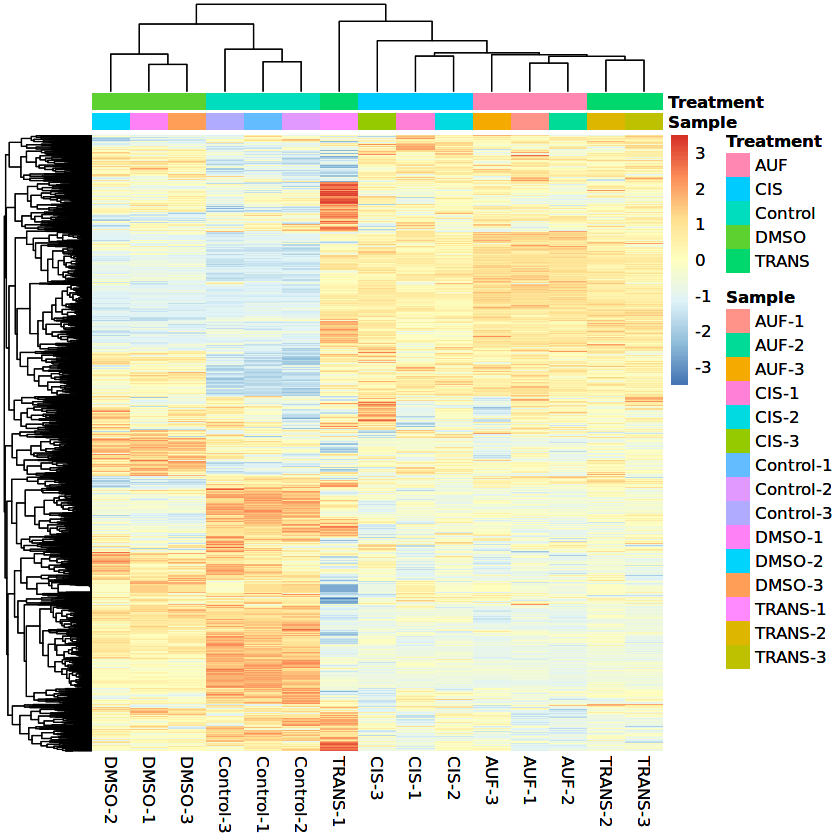

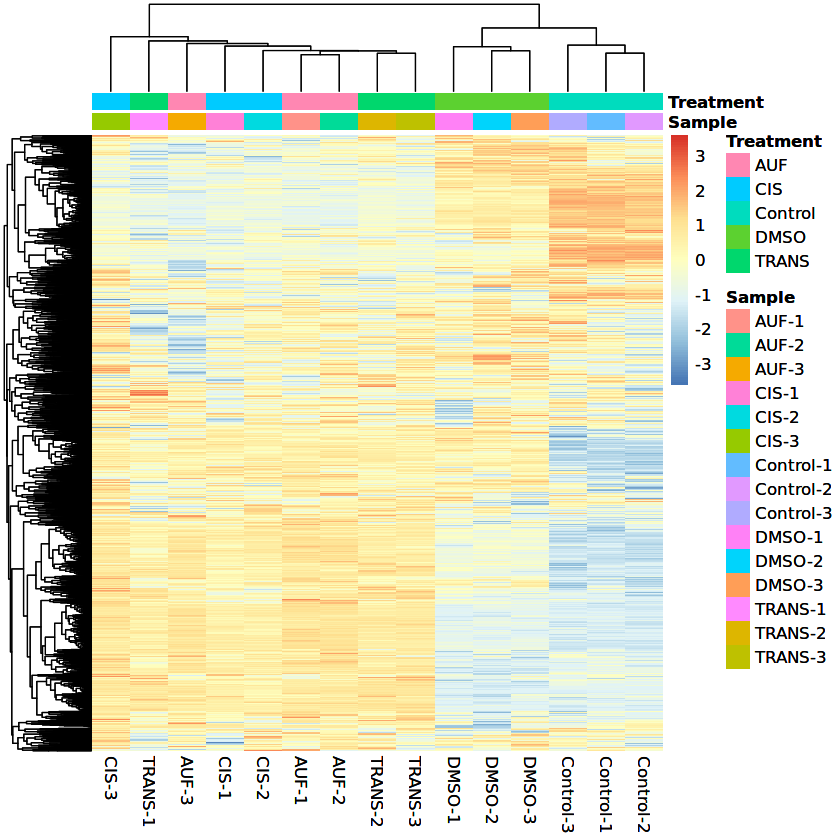

In [20]:
# Define function for filtering top expressing genes and plotting a heatmap

heatmap_plot <- function(x, anno, a="row", f=10){
  library(pheatmap)
  x <- x[order(rowVars(as.matrix(x), useNames = TRUE),decreasing=TRUE),]
  tpm_mat <- as.matrix(x)
  rownames(tpm_mat) <- rownames(x)
  tpm_mat_selected <- tpm_mat[1:2000,]
  #my_hclust_gene <- hclust(dist(tpm_mat_selected), method = "complete")
  #my_gene_col <- as.data.frame(cutree(tree = as.dendrogram(my_hclust_gene), k = f))
  #colnames(my_gene_col) <- "Cluster"
  anno_edit <- anno[colnames(tpm_mat_selected), c("Sample", "Treatment")]
  p <- pheatmap(tpm_mat_selected, scale=a, cluster_rows = T, cluster_cols = T, show_rownames = F, annotation_col = anno_edit)
  return(p)
}

#### z-normalize before clustering ####

# Heatmap for all samples with z-score
heatmap_plot(countsTPM, anno, "row", 10)
heatmap_plot(countsLOG, anno, "row", 10)

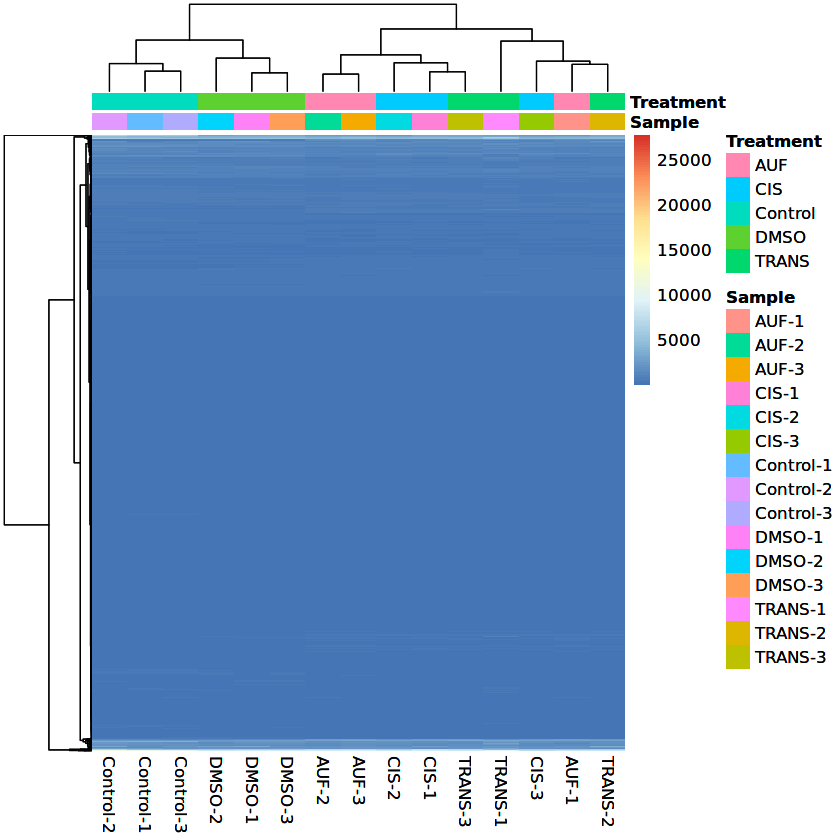

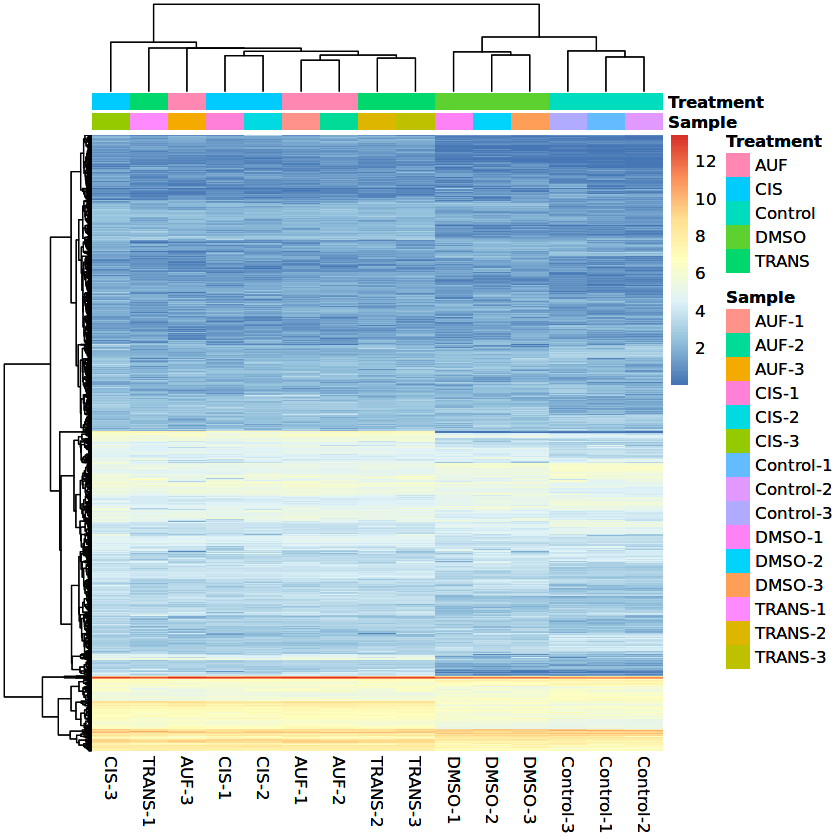

In [21]:
# Define function for filtering top expressing genes and plotting a heatmap

heatmap_plot_unscaled <- function(x, anno, f=10){
  library(pheatmap)
  x <- x[order(rowVars(as.matrix(x), useNames = TRUE),decreasing=TRUE),]
  tpm_mat <- as.matrix(x)
  rownames(tpm_mat) <- rownames(x)
  tpm_mat_selected <- tpm_mat[1:2000,]
  anno_edit <- anno[colnames(tpm_mat_selected), c("Sample", "Treatment")]
  
  # create heatmap without z score normalization 
  p <- pheatmap(tpm_mat_selected, cluster_rows = T, cluster_cols = T, show_rownames = F, annotation_col = anno_edit)
  return(p)
}

# Heatmap for all samples without z-score
heatmap_plot_unscaled(countsTPM, anno, 10)
heatmap_plot_unscaled(countsLOG, anno, 10)

# 6. DE analysis

DESeq2 for identification of DE genes between conditions (for each cell type, compare treatements with each other). More info given in https://bioconductor.org/packages/3.21/bioc/vignettes/DESeq2/inst/doc/DESeq2.html#countmat.

Import the coldata that annotates the samples (colnames) and make sure they are in same order as in raw counts (only raw counts may be put into DESeq2).

DESeq analysis will be performed for each cell type individually here.

DE analysis statistically tests each gene to see whether the difference in expression between groups is larger than expected by random variation.

In [22]:
coldata <- anno
coldata <- coldata[colnames(countsRAW),]
coldata$Treatment <- factor(coldata$Treatment)
coldata$Replicate <- factor(coldata$Replicate)
head(coldata)
dim(coldata)

,Sample,Treatment,Replicate
,<chr>,<fct>,<fct>
Control-1,Control-1,Control,1
Control-2,Control-2,Control,2
Control-3,Control-3,Control,3
DMSO-1,DMSO-1,DMSO,1
DMSO-2,DMSO-2,DMSO,2
DMSO-3,DMSO-3,DMSO,3


[1] 15  3

Raw counts will be used for DE analysis.

In [23]:
head(countsRAW)

,Control-1,Control-2,Control-3,DMSO-1,DMSO-2,DMSO-3,AUF-1,AUF-2,AUF-3,CIS-1,CIS-2,CIS-3,TRANS-1,TRANS-2,TRANS-3
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Mrpl15,948,1970,937,890,757,580,723,776,809,1009,787,817,933,690,843
Lypla1,1331,3014,1522,1704,1795,1418,1330,1513,1408,1969,1361,1590,1596,1386,1535
Tcea1,3288,7526,4206,3457,3569,2345,3271,3922,3921,4342,3588,4198,3442,3158,3611
Atp6v1h,1972,4607,2386,2457,2324,1886,3019,3362,3292,3505,2835,3365,4100,2778,3102
4732440D04Rik,37,91,55,30,89,47,57,72,61,99,72,77,34,43,56
Rb1cc1,1595,3677,1916,2336,2420,1622,2188,2639,2524,2620,2397,2806,2617,2284,2141


## 6.1 DE objects for treatments vs. DMSO

In [24]:
# Function to subset data to dataframe (treatments of interest) for creation of DESeq object

getDEresults <- function(df, coldata, treatment) {

  # subset to tissue (cell state)
  df_select <- df[,c("DMSO-1",	"DMSO-2",	"DMSO-3",
                  "AUF-1",	"AUF-2",	"AUF-3",
                  "CIS-1",	"CIS-2",	"CIS-3",
                  "TRANS-1",	"TRANS-2",	"TRANS-3")]

  # metadata for the selected samples
  coldata_select <- coldata[colnames(df_select), c("Treatment", "Replicate")]
  coldata_select <- dplyr::filter(coldata_select, Treatment %in% c("DMSO", treatment))

  # set factor levels so DESeq2 contrast works
  coldata_select$Treatment  <- factor(coldata_select$Treatment, levels = c("DMSO", treatment))
  coldata_select$Replicate  <- factor(coldata_select$Replicate)

  # reorder columns to match coldata_select row order
  df_select <- df_select[, rownames(coldata_select), drop = FALSE]

  # Gene filtering
  min_samples <- ceiling(ncol(df_select) * 0.5)
  keep <- rowSums(df_select > 10) >= min_samples
  df_select <- df_select[keep, ]

  # DESeq2
  dds <- DESeq2::DESeqDataSetFromMatrix(
    countData = round(df_select),
    colData   = coldata_select,
    design    = ~ Treatment
  )
  dds <- DESeq2::DESeq(dds)

  # return ONE object: a named list
  return(list(
    dds = dds,
    coldata_select = coldata_select,
    df = df_select
  ))
}

# Function to get results for specific contrasts (comparisons), plot MAplot and get list of DEgenes between conditions.

getDEanalysis <- function(dds, comparison, countData, coldata){
  res <- results(dds, contrast = comparison, alpha = 0.05) # significance threshold for adjusted p-value of 5 %
  plotMA(res, ylim = c(-8,8), main = paste0(comparison[2],"_vs_",comparison[3]))
  summary(res)
  print(paste0("Significant DE genes at adjusted p-value of 0.05: ", sum(res$padj < 0.05, na.rm=TRUE)))
  resOrdered <- res[order(res$padj),]
  resSig <- subset(resOrdered, padj < 0.05)
  df <- countData[rownames(resSig),order(colnames(countData))]
  anno <- coldata[colnames(df), c("Treatment", "Replicate")]
  if ((length(rownames(resSig)) < 30) & (length(rownames(resSig)) > 1)){
    pheatmap(df, cluster_cols = FALSE, scale = "row", cluster_rows = TRUE, annotation_col = anno)
  } else if (length(rownames(resSig)) >= 30) {
    pheatmap(df, cluster_cols = FALSE, scale = "row", cluster_rows = TRUE, show_rownames = FALSE, annotation_col = anno)
  }
  
  return(resSig)
}

# Function to perform a comprehensive DE and enrichment analysis 

getDEanalysisFull <- function(dds, comparison, countData, coldata, ontology = "BP", nTopGO = 15) {

  library(topGO)
  library(org.Mm.eg.db)
  library(AnnotationDbi)
  library(ggplot2)
  library(pheatmap)

  ## ──────────────────────────────────────────────
  ## Differential expression
  ## ──────────────────────────────────────────────

  res <- results(dds, contrast = comparison, alpha = 0.05)
  res_shrunk <- DESeq2::lfcShrink(dds, contrast = comparison, type = "ashr")
  res_shrunk <- res_shrunk[!is.na(res_shrunk$log2FoldChange) & abs(res_shrunk$log2FoldChange) <= 10, ]
  resOrdered <- res_shrunk[order(res_shrunk$padj), ]
  resSig <- subset(resOrdered, padj < 0.05)

  message("Significant DE genes (padj < 0.05): ", nrow(resSig))

  ## Volcano plot
  res_df <- as.data.frame(res_shrunk)
  res_df$gene <- rownames(res_df)
  res_df$neglog10padj <- -log10(res_df$padj)
  res_df$sig <- ifelse(res_df$padj < 0.05, "Significant", "Not significant")

  volcano_plot <- ggplot(res_df, aes(x = log2FoldChange, y = neglog10padj, color = sig)) +
    geom_point(alpha=0.7) +
    scale_color_manual(values = c("grey", "#D55E00")) +
    ggrepel::geom_text_repel(
      data = subset(res_df, padj < 0.05),
      aes(label = gene),
      size = 2.5,
      max.overlaps = 20,
      color = "black"
    ) +
    labs(title="Volcano Plot", x="log2 Fold Change", y="-log10(adjusted p)") +
    theme_bw() +
    xlim(-10, 10) +
    ylim(0, 12.5)

  ## ──────────────────────────────────────────────
  ## Split into over- and under-expressed sets
  ## ──────────────────────────────────────────────
  res_over  <- subset(resSig, log2FoldChange > 0)
  res_under <- subset(resSig, log2FoldChange < 0)

  message("Over-expressed genes: ", nrow(res_over))
  message("Under-expressed genes: ", nrow(res_under))

  ## Helper function to perform topGO and generate plots
  run_topGO <- function(sigGenes, universeGenes, label) {

    if (length(sigGenes) < 5) {
      message("Skipping topGO for ", label, " — not enough significant genes.")
      return(list(results=NULL, bar=NULL, dot=NULL))
    }

    geneList <- factor(as.integer(universeGenes %in% sigGenes))
    names(geneList) <- universeGenes

    geneID2GO <- annFUN.org(
      whichOnto = ontology,
      feasibleGenes = universeGenes,
      mapping = "org.Mm.eg.db",
      ID = "SYMBOL"
    )

    GOdata <- new("topGOdata",
                  ontology = ontology,
                  allGenes = geneList,
                  annot = annFUN.GO2genes,
                  GO2genes = geneID2GO,
                  nodeSize = 5)

    resultFisher <- runTest(GOdata, algorithm="weight01", statistic="fisher")

    goRes <- GenTable(GOdata,
                      Fisher = resultFisher,
                      orderBy = "Fisher",
                      topNodes = length(score(resultFisher)),
                      numChar = 1000)
    goRes$Fisher <- as.numeric(goRes$Fisher)
    goRes <- goRes[goRes$Fisher < 0.05, ]

    if (nrow(goRes) == 0) {
      message("No GO terms enriched for ", label)
      return(list(results=goRes, bar=NULL, dot=NULL))
    }

    ## Select top N
    topN <- min(nTopGO, nrow(goRes))
    goTop <- goRes[1:topN, ]
    goTop$GeneRatio <- goTop$Significant / goTop$Annotated
    goTop$Term <- make.unique(as.character(goTop$Term))
    # goTop$Term <- factor(goTop$Term, levels = rev(goTop$Term))
    # Wrap long GO term names onto multiple lines
    goTop$Term_wrapped <- str_wrap(goTop$Term, width = 50)

    # Preserve plotting order
    goTop$Term_wrapped <- factor(goTop$Term_wrapped, levels = rev(goTop$Term_wrapped))

    ## Bar plot
    barplot <- ggplot(goTop, aes(x = Term_wrapped, y = -log10(Fisher))) +
      geom_bar(stat="identity", fill="#0072B2") +
      coord_flip() +
      labs(title=paste("Top", topN, ontology, "GO Terms —", label),
           y="-log10(p-value)", x="") +
      theme_bw()

    dotplot <- ggplot(goTop, aes(x = -log10(Fisher), y = Term_wrapped, size = GeneRatio)) +
  geom_point(color = "#D55E00") +
  scale_size_continuous(name = "Gene Ratio\n(DEGs/Annotated)") +
  labs(title = paste("GO Enrichment Dotplot —", label),
       x = "-log10(p-value)", y = "") +
  theme_bw()

    return(list(results=goRes, bar=barplot, dot=dotplot))
  }

  universe <- rownames(res_shrunk)

  ## Run GO for over- and under-expressed genes
  GO_over  <- run_topGO(rownames(res_over), universe, "Over-expressed")
  GO_under <- run_topGO(rownames(res_under), universe, "Under-expressed")

  ## Return everything
  return(list(
    DEgenes_over   = res_over,
    DEgenes_under  = res_under,
    GOresults_over = GO_over$results,
    GOresults_under = GO_under$results,
    GOplots = list(
      over = list(bar = GO_over$bar, dot = GO_over$dot),
      under = list(bar = GO_under$bar, dot = GO_under$dot)
    ),
    Volcanoplot = volcano_plot
  ))
}

In [25]:
getAnywhere(getDEresults)

A single object matching ‘getDEresults’ was found
It was found in the following places
  .GlobalEnv
with value

<srcref: file "" chars 3:17 to 41:1>

### Run DE analysis for AUF, CIS and TRANS against DMSO

converting counts to integer mode

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



  DMSO-1   DMSO-2   DMSO-3    AUF-1    AUF-2    AUF-3 
25230379 24769665 18653542 20226415 22524611 22153753 

out of 15494 with nonzero total read count
adjusted p-value < 0.05
LFC > 0 (up)       : 2025, 13%
LFC < 0 (down)     : 1645, 11%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 8)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results

[1] "Significant DE genes at adjusted p-value of 0.05: 3670"


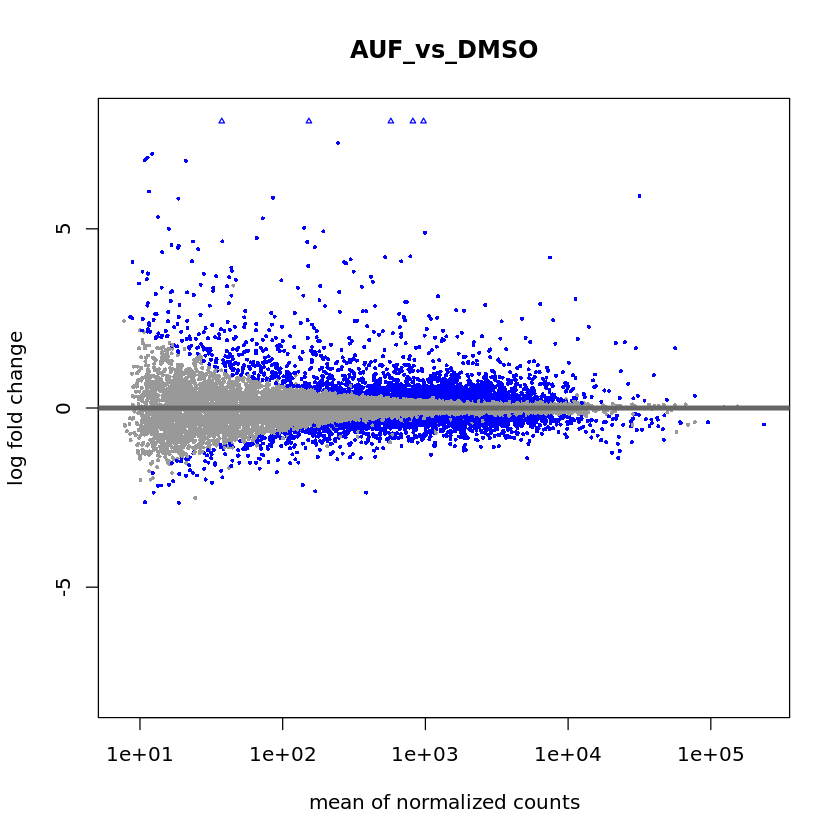

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

Significant DE genes (padj < 0.05): 3669

Over-expressed genes: 2024

Under-expressed genes: 1645


Building most specific GOs .....

	( 11160 GO terms found. )


Build GO DAG topology ..........

	( 14508 GO terms and 32512 relations. )


Annotating nodes ...............

	( 13186 genes annotated to the GO terms. )


			 -- Weight01 Algorithm -- 

		 the algorithm is scoring 7202 nontrivial nodes
		 parameters: 
			 test statistic: fisher


	 Level 18:	2 nodes to be scored	(0 eliminated genes)


	 Level 17:	10 nodes to be scored	(0 eliminated genes)


	 Level 16:	33 nodes to be scored	(28 eliminated genes)


	 Level 15:	53 nodes to be scored	(97 eliminated genes)


	 Level 14:	94 nodes to be scored	(296 eliminated genes)


	 Level 13:	196 nodes to be scored	(635 eliminated genes)




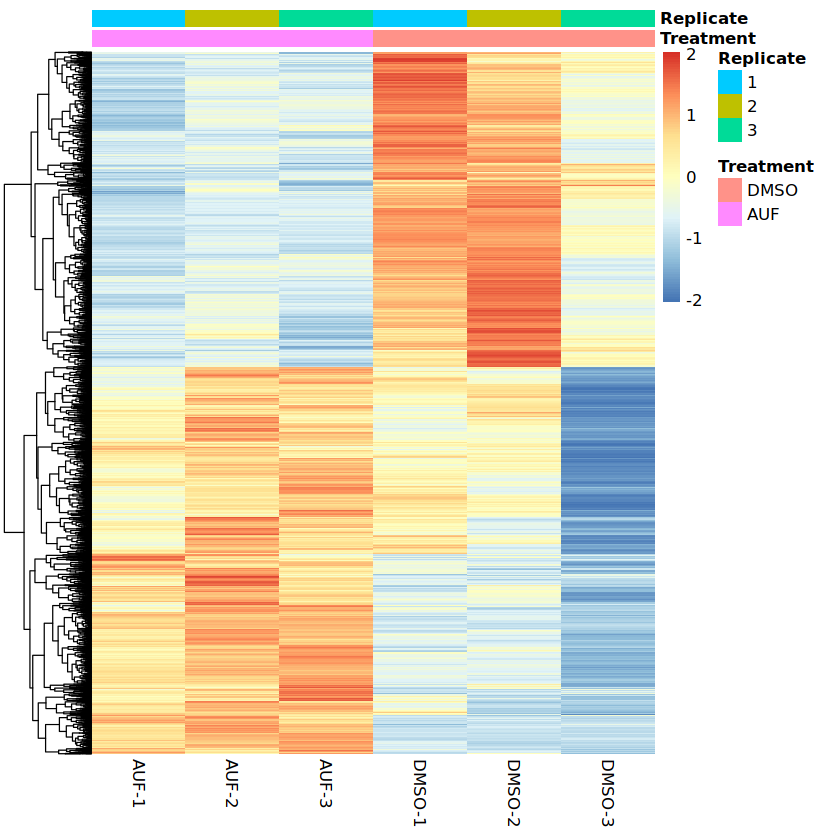

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call.graphics(C_text, as.

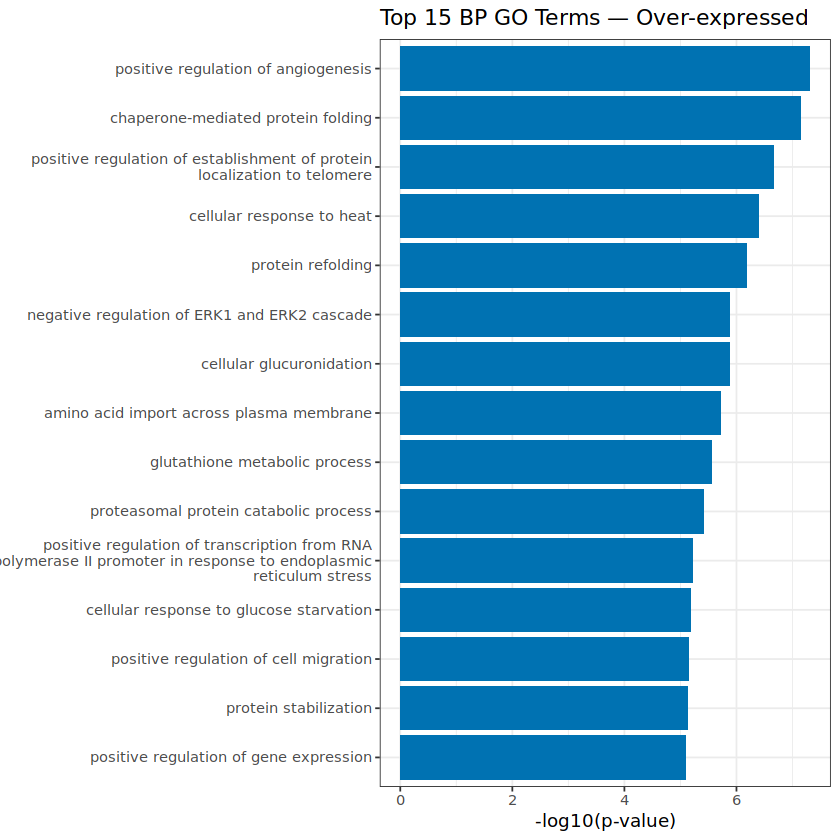

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call.graphics(C_text, as.graphicsAn

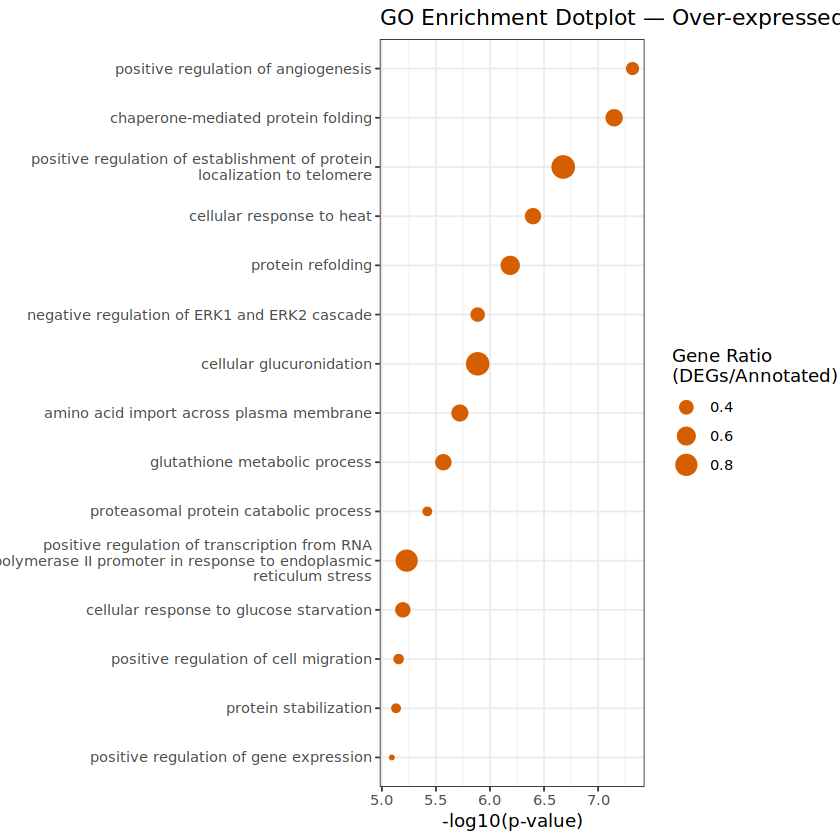

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call.graphics(C_text

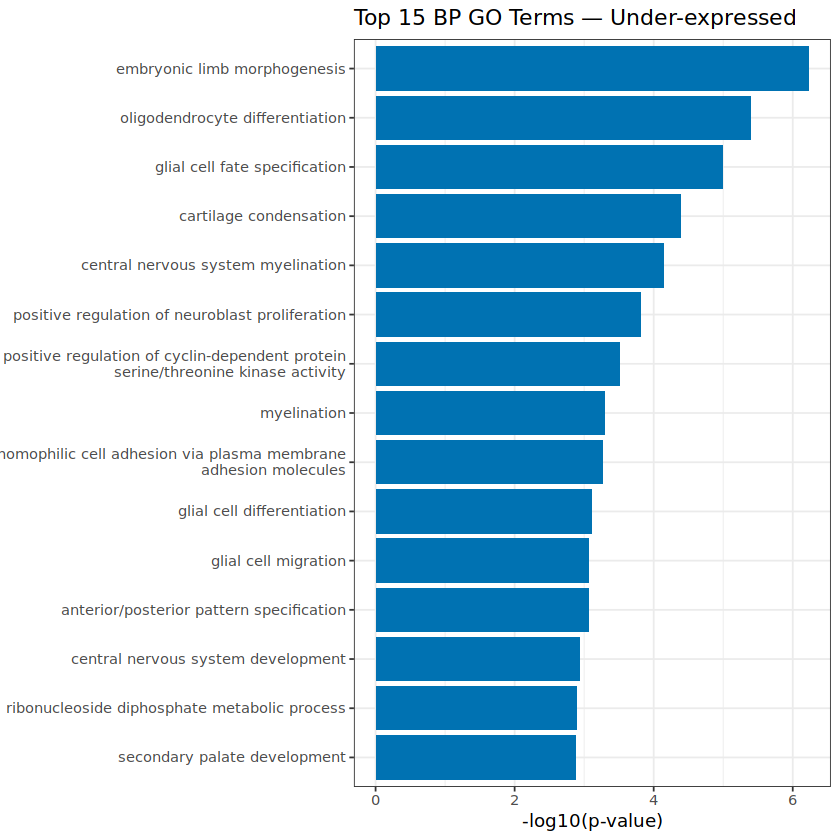

[1] "..."


converting counts to integer mode

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



  DMSO-1   DMSO-2   DMSO-3    CIS-1    CIS-2    CIS-3 
25231340 24770866 18654263 26044650 22307344 25856384 


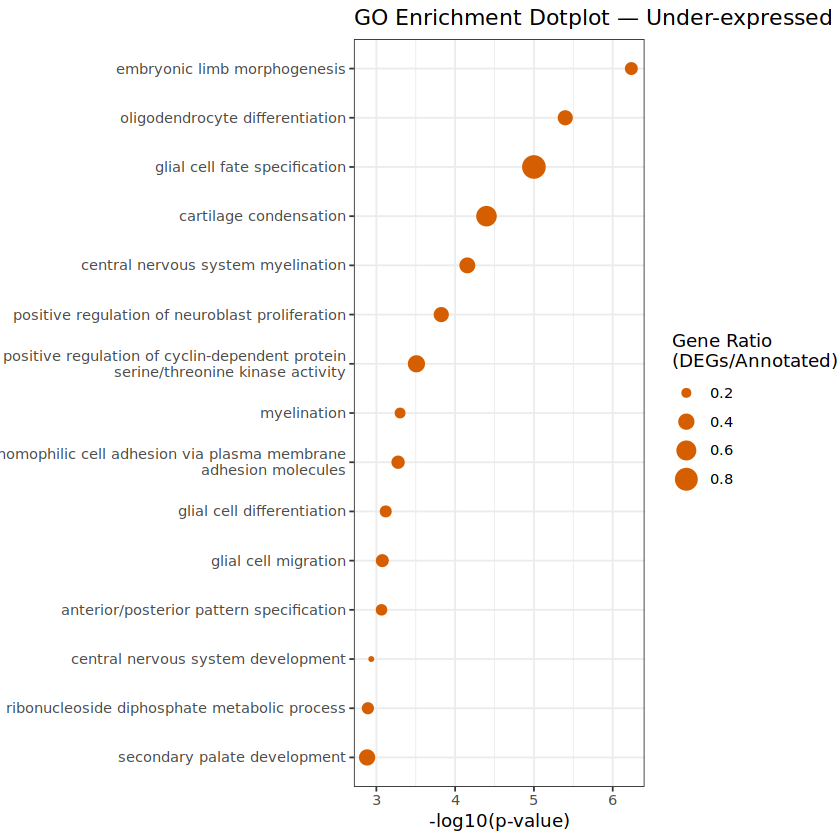


out of 15579 with nonzero total read count
adjusted p-value < 0.05
LFC > 0 (up)       : 1316, 8.4%
LFC < 0 (down)     : 953, 6.1%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 7)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results

[1] "Significant DE genes at adjusted p-value of 0.05: 2269"


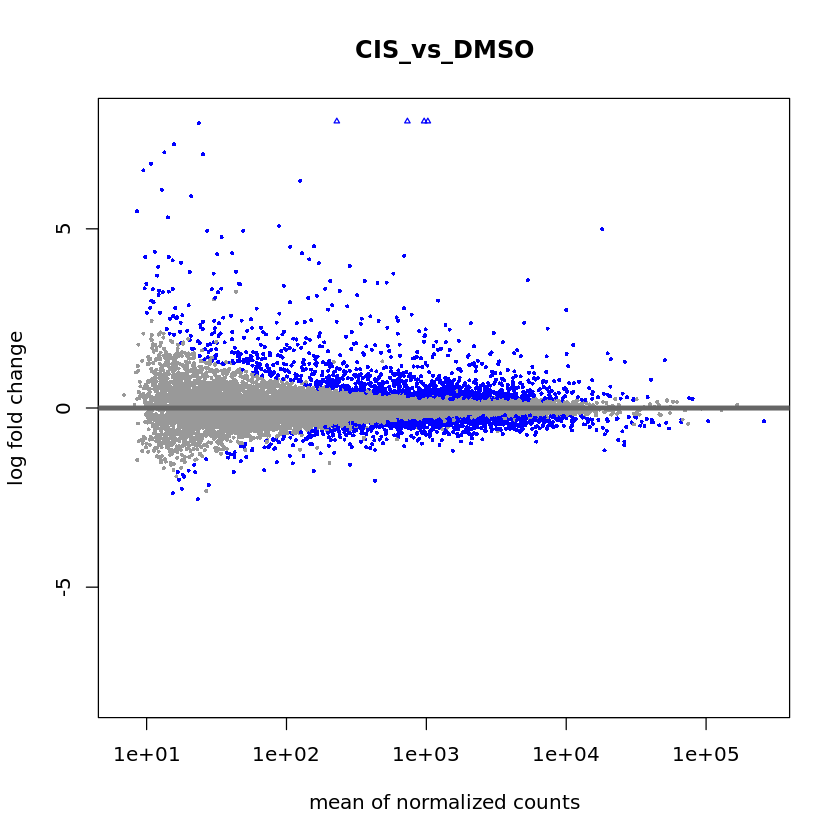

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

Significant DE genes (padj < 0.05): 2268

Over-expressed genes: 1315

Under-expressed genes: 953


Building most specific GOs .....

	( 11161 GO terms found. )


Build GO DAG topology ..........

	( 14519 GO terms and 32522 relations. )


Annotating nodes ...............

	( 13232 genes annotated to the GO terms. )


			 -- Weight01 Algorithm -- 

		 the algorithm is scoring 6571 nontrivial nodes
		 parameters: 
			 test statistic: fisher


	 Level 18:	2 nodes to be scored	(0 eliminated genes)


	 Level 17:	11 nodes to be scored	(0 eliminated genes)


	 Level 16:	31 nodes to be scored	(29 eliminated genes)


	 Level 15:	47 nodes to be scored	(101 eliminated genes)


	 Level 14:	87 nodes to be scored	(281 eliminated genes)


	 Level 13:	170 nodes to be scored	(587 eliminated genes)




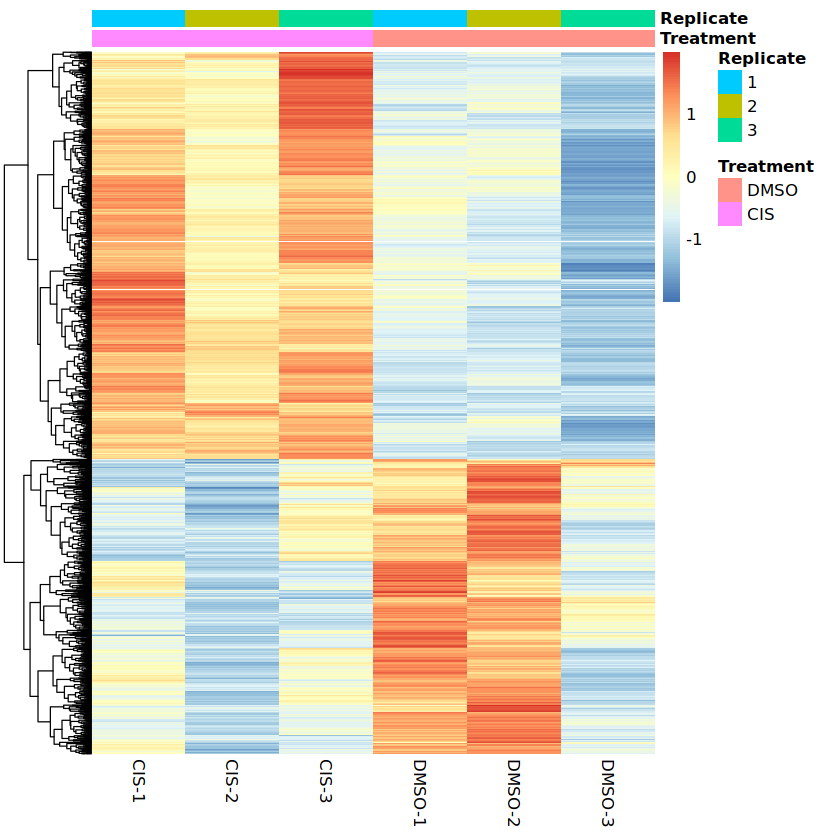

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call.graphics(C_text, as.

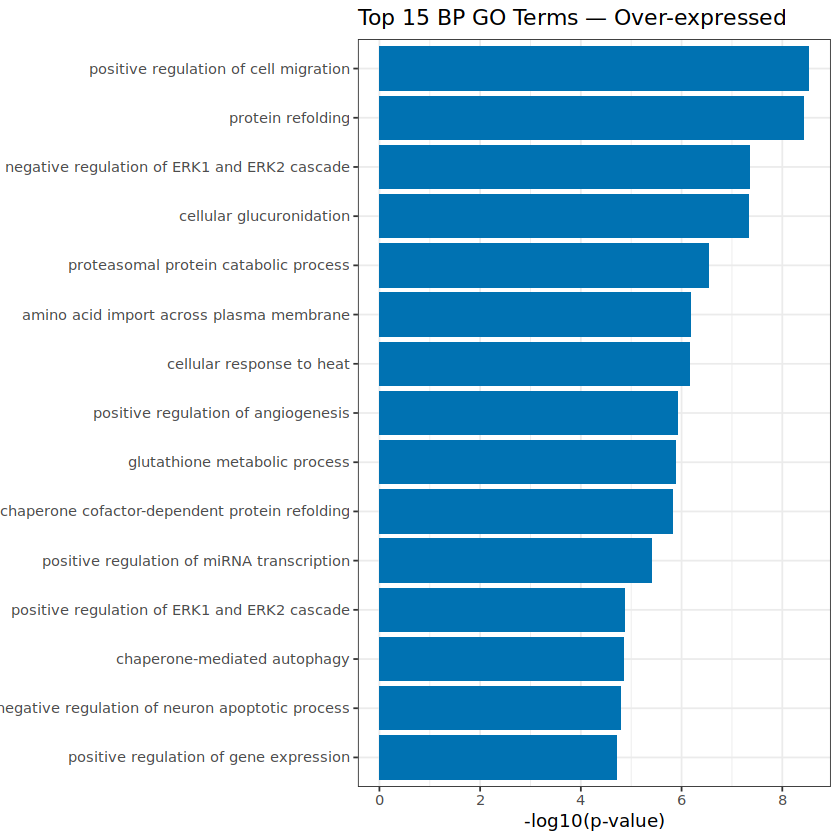

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call.graphics(C_text, as.graphicsAn

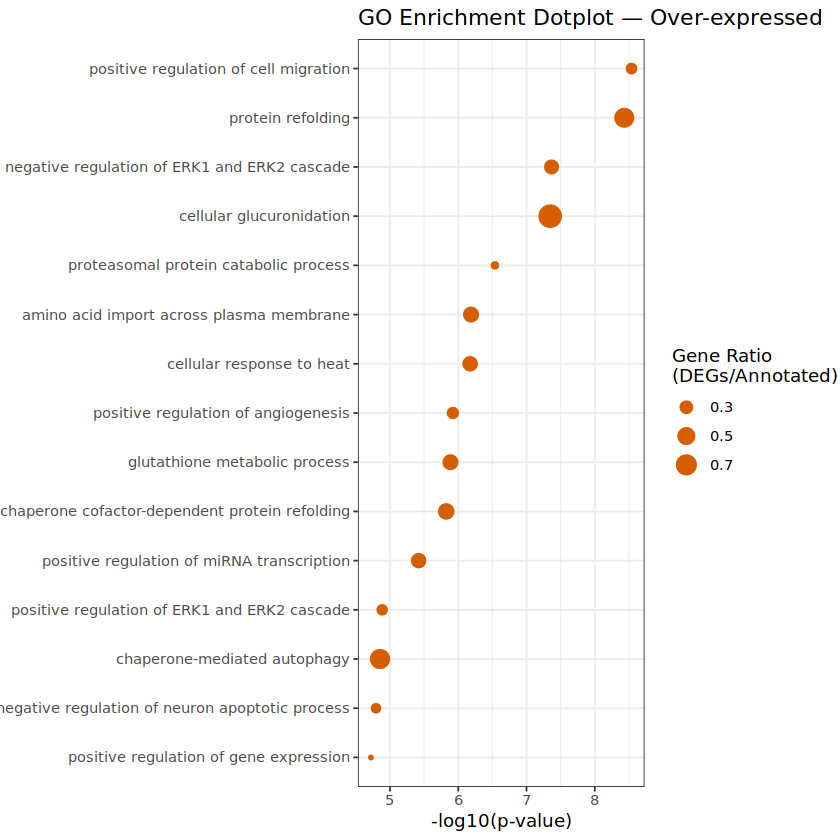

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call.graphics(C_text

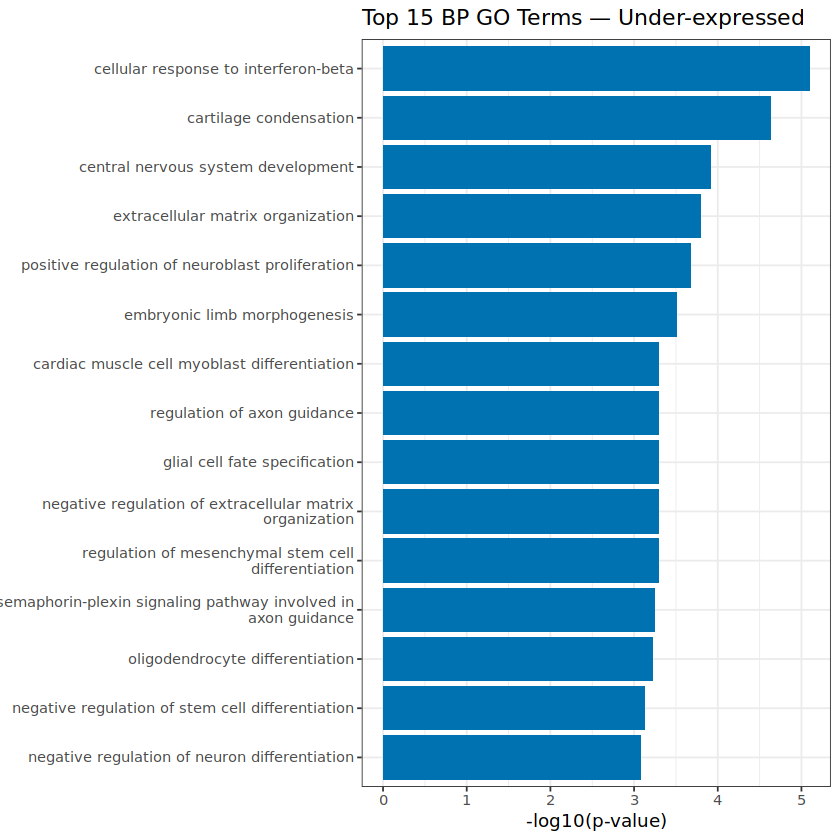

[1] "..."


converting counts to integer mode

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



  DMSO-1   DMSO-2   DMSO-3  TRANS-1  TRANS-2  TRANS-3 
25230784 24770221 18653967 22102122 21100782 22032922 


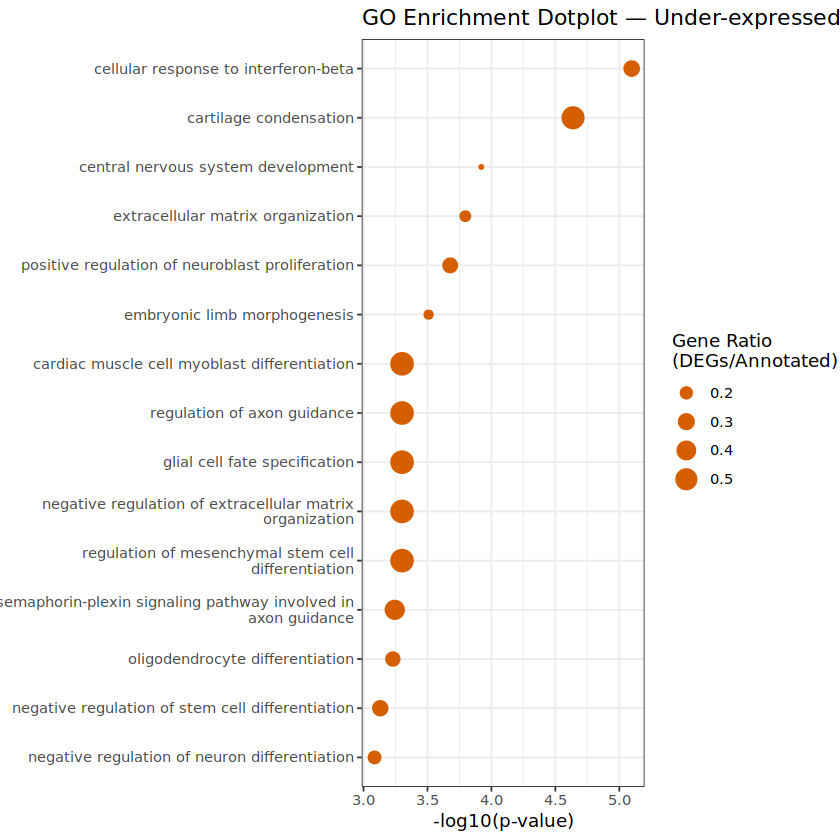


out of 15547 with nonzero total read count
adjusted p-value < 0.05
LFC > 0 (up)       : 1729, 11%
LFC < 0 (down)     : 1295, 8.3%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 8)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results

[1] "Significant DE genes at adjusted p-value of 0.05: 3024"


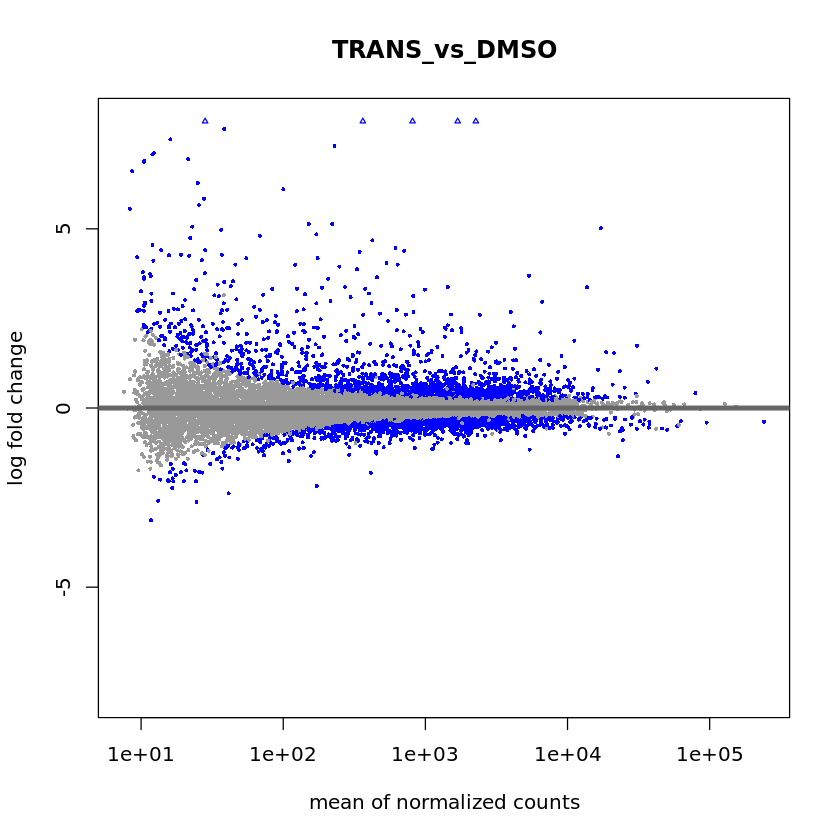

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

Significant DE genes (padj < 0.05): 3022

Over-expressed genes: 1727

Under-expressed genes: 1295


Building most specific GOs .....

	( 11161 GO terms found. )


Build GO DAG topology ..........

	( 14506 GO terms and 32515 relations. )


Annotating nodes ...............

	( 13216 genes annotated to the GO terms. )


			 -- Weight01 Algorithm -- 

		 the algorithm is scoring 6982 nontrivial nodes
		 parameters: 
			 test statistic: fisher


	 Level 18:	2 nodes to be scored	(0 eliminated genes)


	 Level 17:	10 nodes to be scored	(0 eliminated genes)


	 Level 16:	31 nodes to be scored	(28 eliminated genes)


	 Level 15:	49 nodes to be scored	(95 eliminated genes)


	 Level 14:	94 nodes to be scored	(286 eliminated genes)


	 Level 13:	187 nodes to be scored	(606 eliminated genes)




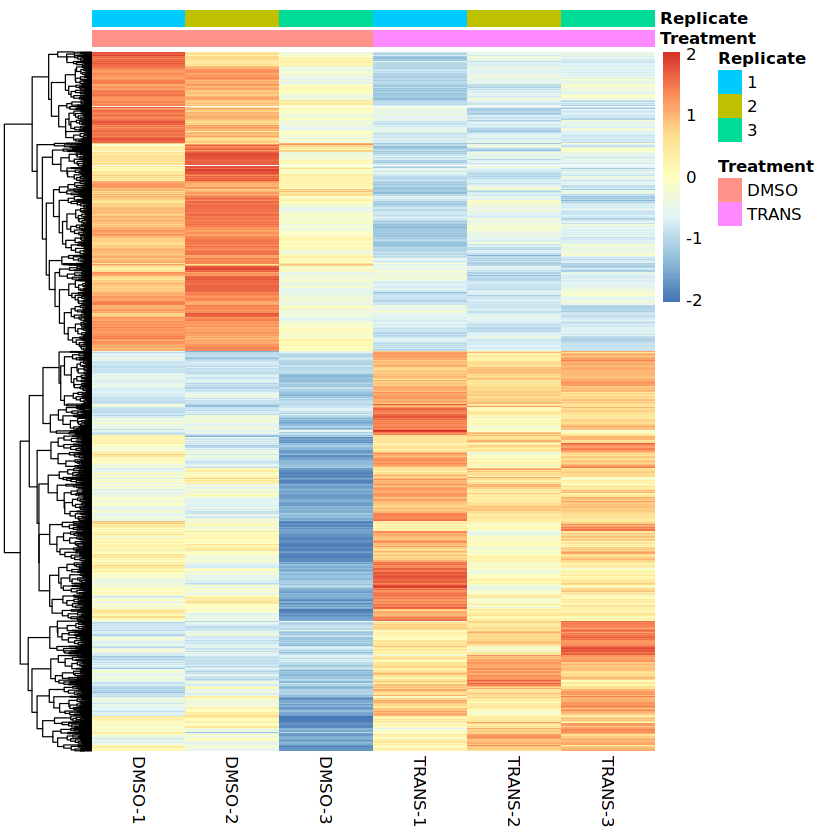

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call.graphics(C_text, as.

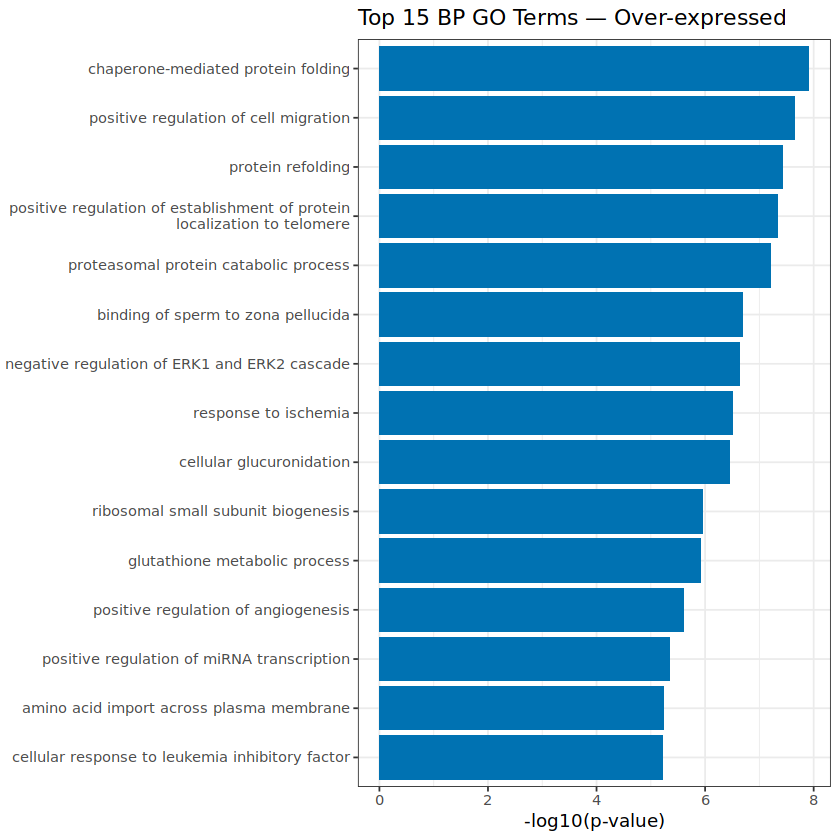

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call.graphics(C_text, as.graphicsAn

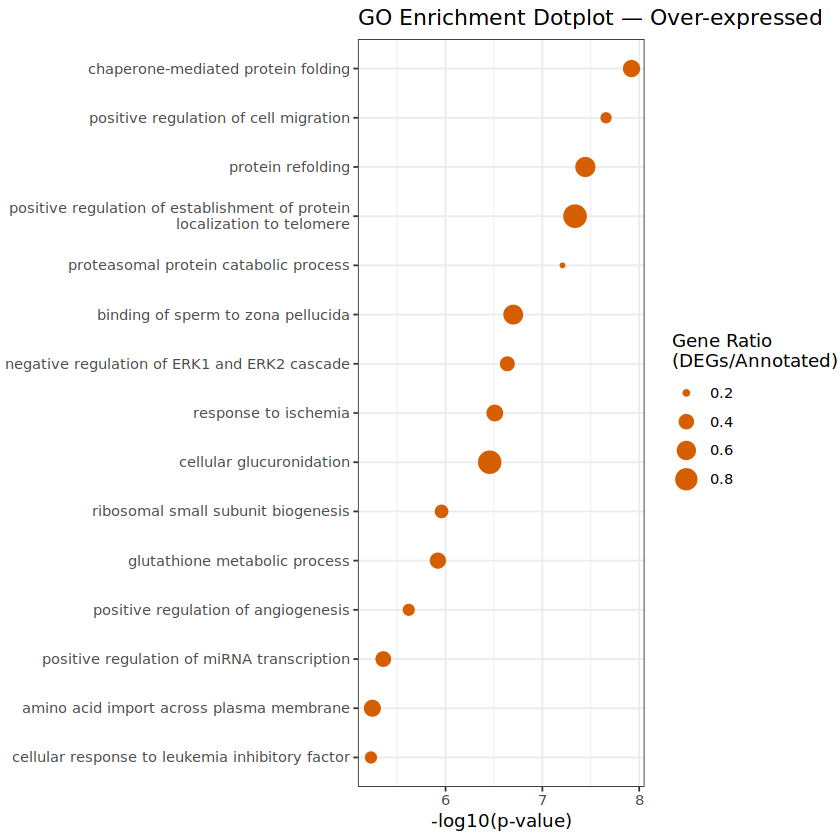

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call.graphics(C_text

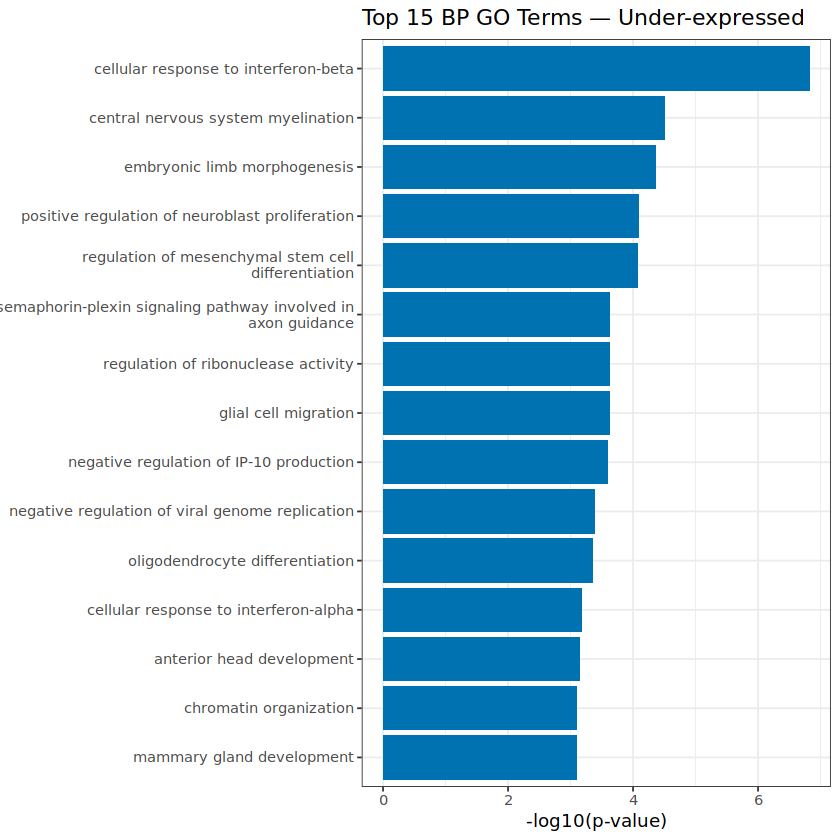

[1] "..."


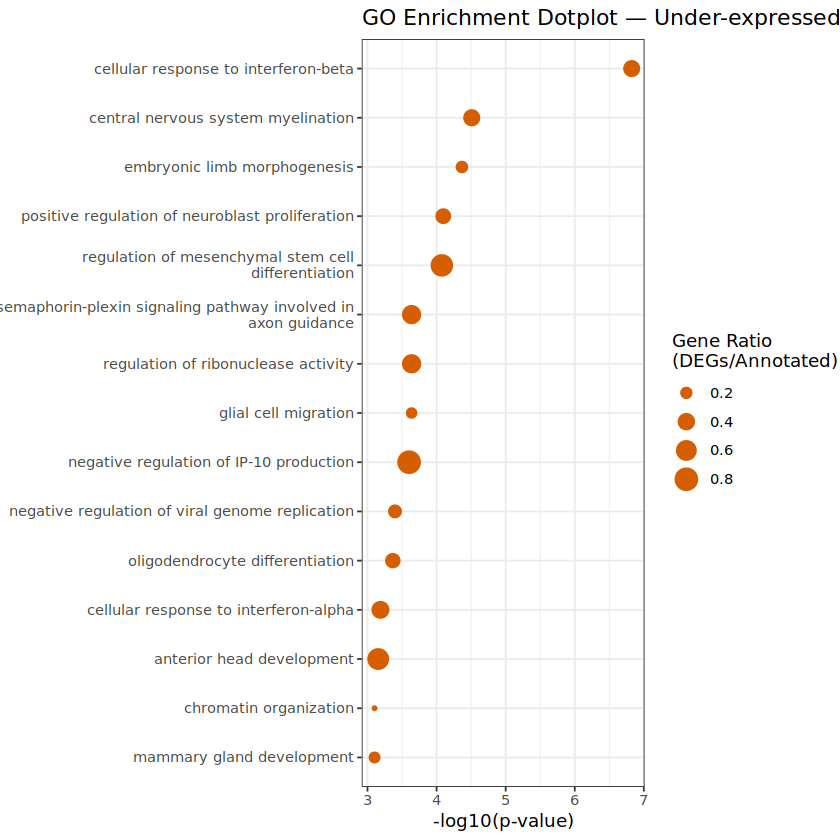

In [26]:
library(writexl)
for (treatment in c("AUF", "CIS", "TRANS")) {

  res <- getDEresults(countsRAW, coldata, treatment)
  dds <- res$dds
  coldata_select <- res$coldata_select
  df <- res$df

  print(colSums(df))

  contrast <- c("Treatment", treatment, "DMSO")
  sig <- getDEanalysis(dds, contrast, df, coldata_select)

  if (nrow(sig) > 0) {
    sig_new <- getDEanalysisFull(dds, contrast, df, coldata_select)
    pdf(paste0("Volcano_plot_", treatment, ".pdf"))
    print(sig_new$Volcanoplot)
    dev.off()
    write_xlsx(data.frame(sig_new$DEgenes_over), paste0("DEGs_", treatment, "_upregulated.xlsx"))
    write_xlsx(data.frame(sig_new$DEgenes_under), paste0("DEGs_", treatment, "_downregulated.xlsx"))
    print(sig_new$GOplots$over$bar)
    pdf(paste0("GOplot_over_", treatment, ".pdf"))
    print(sig_new$GOplots$over$dot)
    dev.off()
    print(sig_new$GOplots$over$dot)
    print(sig_new$GOplots$under$bar)
    pdf(paste0("GOplot_under_", treatment, ".pdf"))
    print(sig_new$GOplots$under$dot)
    dev.off()
    print(sig_new$GOplots$under$dot)
    write_xlsx(data.frame(sig_new$GOresults_over), paste0("GOterms_", treatment, "_upregulated.xlsx"))
    write_xlsx(data.frame(sig_new$GOresults_under), paste0("GOterms_", treatment, "_downregulated.xlsx"))
    print("...")
  }
}

### Compare TRANS vs. CIS

In [27]:
# Function to subset data to dataframe (treatments of interest) for creation of DESeq object

getDEresults <- function(df, coldata, treatment) {

  # subset to tissue (cell state)
  df_select <- df[,c("CIS-1",	"CIS-2",	"CIS-3",
                  "TRANS-1",	"TRANS-2",	"TRANS-3")]

  # metadata for the selected samples
  coldata_select <- coldata[colnames(df_select), c("Treatment", "Replicate")]
  coldata_select <- dplyr::filter(coldata_select, Treatment %in% c("CIS", treatment))

  # set factor levels so DESeq2 contrast works
  coldata_select$Treatment  <- factor(coldata_select$Treatment, levels = c("CIS", treatment))
  coldata_select$Replicate  <- factor(coldata_select$Replicate)

  # reorder columns to match coldata_select row order
  df_select <- df_select[, rownames(coldata_select), drop = FALSE]

  # Gene filtering
  min_samples <- ceiling(ncol(df_select) * 0.5)
  keep <- rowSums(df_select > 10) >= min_samples
  df_select <- df_select[keep, ]

  # DESeq2
  dds <- DESeq2::DESeqDataSetFromMatrix(
    countData = round(df_select),
    colData   = coldata_select,
    design    = ~ Treatment
  )
  dds <- DESeq2::DESeq(dds)

  # return ONE object: a named list
  return(list(
    dds = dds,
    coldata_select = coldata_select,
    df = df_select
  ))
}

# Function to get results for specific contrasts (comparisons), plot MAplot and get list of DEgenes between conditions.

getDEanalysis <- function(dds, comparison, countData, coldata){
  res <- results(dds, contrast = comparison, alpha = 0.05) # significance threshold for adjusted p-value of 5 %
  plotMA(res, ylim = c(-8,8), main = paste0(comparison[2],"_vs_",comparison[3]))
  summary(res)
  print(paste0("Significant DE genes at adjusted p-value of 0.05: ", sum(res$padj < 0.05, na.rm=TRUE)))
  resOrdered <- res[order(res$padj),]
  resSig <- subset(resOrdered, padj < 0.05)
  df <- countData[rownames(resSig),order(colnames(countData))]
  anno <- coldata[colnames(df), c("Treatment", "Replicate")]
  if ((length(rownames(resSig)) < 30) & (length(rownames(resSig)) > 1)){
    pheatmap(df, cluster_cols = FALSE, scale = "row", cluster_rows = TRUE, annotation_col = anno)
  } else if (length(rownames(resSig)) >= 30) {
    pheatmap(df, cluster_cols = FALSE, scale = "row", cluster_rows = TRUE, show_rownames = FALSE, annotation_col = anno)
  }
  
  return(resSig)
}

# Function to perform a comprehensive DE and enrichment analysis 

getDEanalysisFull <- function(dds, comparison, countData, coldata, ontology = "BP", nTopGO = 15) {

  library(topGO)
  library(org.Mm.eg.db)
  library(AnnotationDbi)
  library(ggplot2)
  library(pheatmap)

  ## ──────────────────────────────────────────────
  ## Differential expression
  ## ──────────────────────────────────────────────

  res <- results(dds, contrast = comparison, alpha = 0.05)
  res_shrunk <- DESeq2::lfcShrink(dds, contrast = comparison, type = "ashr")
  res_shrunk <- res_shrunk[!is.na(res_shrunk$log2FoldChange) & abs(res_shrunk$log2FoldChange) <= 10, ]
  resOrdered <- res_shrunk[order(res_shrunk$padj), ]
  resSig <- subset(resOrdered, padj < 0.05)

  message("Significant DE genes (padj < 0.05): ", nrow(resSig))

  ## Volcano plot
  res_df <- as.data.frame(res_shrunk)
  res_df$gene <- rownames(res_df)
  res_df$neglog10padj <- -log10(res_df$padj)
  res_df$sig <- ifelse(res_df$padj < 0.05, "Significant", "Not significant")

  volcano_plot <- ggplot(res_df, aes(x = log2FoldChange, y = neglog10padj, color = sig)) +
    geom_point(alpha=0.7) +
    scale_color_manual(values = c("grey", "#D55E00")) +
    ggrepel::geom_text_repel(
      data = subset(res_df, padj < 0.05),
      aes(label = gene),
      size = 2.5,
      max.overlaps = 20,
      color = "black"
    ) +
    labs(title="Volcano Plot", x="log2 Fold Change", y="-log10(adjusted p)") +
    theme_bw() +
    xlim(-10, 10) +
    ylim(0, 12.5)

  ## ──────────────────────────────────────────────
  ## Split into over- and under-expressed sets
  ## ──────────────────────────────────────────────
  res_over  <- subset(resSig, log2FoldChange > 0)
  res_under <- subset(resSig, log2FoldChange < 0)

  message("Over-expressed genes: ", nrow(res_over))
  message("Under-expressed genes: ", nrow(res_under))

  ## Helper function to perform topGO and generate plots
  run_topGO <- function(sigGenes, universeGenes, label) {

    if (length(sigGenes) < 5) {
      message("Skipping topGO for ", label, " — not enough significant genes.")
      return(list(results=NULL, bar=NULL, dot=NULL))
    }

    geneList <- factor(as.integer(universeGenes %in% sigGenes))
    names(geneList) <- universeGenes

    geneID2GO <- annFUN.org(
      whichOnto = ontology,
      feasibleGenes = universeGenes,
      mapping = "org.Mm.eg.db",
      ID = "SYMBOL"
    )

    GOdata <- new("topGOdata",
                  ontology = ontology,
                  allGenes = geneList,
                  annot = annFUN.GO2genes,
                  GO2genes = geneID2GO,
                  nodeSize = 5)

    resultFisher <- runTest(GOdata, algorithm="weight01", statistic="fisher")

    goRes <- GenTable(GOdata,
                      Fisher = resultFisher,
                      orderBy = "Fisher",
                      topNodes = length(score(resultFisher)),
                      numChar = 1000)
    goRes$Fisher <- as.numeric(goRes$Fisher)
    goRes <- goRes[goRes$Fisher < 0.05, ]

    if (nrow(goRes) == 0) {
      message("No GO terms enriched for ", label)
      return(list(results=goRes, bar=NULL, dot=NULL))
    }

    ## Select top N
    topN <- min(nTopGO, nrow(goRes))
    goTop <- goRes[1:topN, ]
    goTop$GeneRatio <- goTop$Significant / goTop$Annotated
    goTop$Term <- make.unique(as.character(goTop$Term))
    # goTop$Term <- factor(goTop$Term, levels = rev(goTop$Term))
    # Wrap long GO term names onto multiple lines
    goTop$Term_wrapped <- str_wrap(goTop$Term, width = 50)

    # Preserve plotting order
    goTop$Term_wrapped <- factor(goTop$Term_wrapped, levels = rev(goTop$Term_wrapped))

    ## Bar plot
    barplot <- ggplot(goTop, aes(x = Term_wrapped, y = -log10(Fisher))) +
      geom_bar(stat="identity", fill="#0072B2") +
      coord_flip() +
      labs(title=paste("Top", topN, ontology, "GO Terms —", label),
           y="-log10(p-value)", x="") +
      theme_bw()

    dotplot <- ggplot(goTop, aes(x = -log10(Fisher), y = Term_wrapped, size = GeneRatio)) +
  geom_point(color = "#D55E00") +
  scale_size_continuous(name = "Gene Ratio\n(DEGs/Annotated)") +
  labs(title = paste("GO Enrichment Dotplot —", label),
       x = "-log10(p-value)", y = "") +
  theme_bw()

    return(list(results=goRes, bar=barplot, dot=dotplot))
  }

  universe <- rownames(res_shrunk)

  ## Run GO for over- and under-expressed genes
  GO_over  <- run_topGO(rownames(res_over), universe, "Over-expressed")
  GO_under <- run_topGO(rownames(res_under), universe, "Under-expressed")

  ## Return everything
  return(list(
    DEgenes_over   = res_over,
    DEgenes_under  = res_under,
    GOresults_over = GO_over$results,
    GOresults_under = GO_under$results,
    GOplots = list(
      over = list(bar = GO_over$bar, dot = GO_over$dot),
      under = list(bar = GO_under$bar, dot = GO_under$dot)
    ),
    Volcanoplot = volcano_plot
  ))
}

In [28]:
# packageVersion("topGO")

In [29]:
# install.packages("ashr")

converting counts to integer mode

estimating size factors

estimating dispersions

gene-wise dispersion estimates



mean-dispersion relationship

final dispersion estimates

fitting model and testing



   CIS-1    CIS-2    CIS-3  TRANS-1  TRANS-2  TRANS-3 
26045209 22307858 25857276 22102848 21101532 22034082 

out of 15602 with nonzero total read count
adjusted p-value < 0.05
LFC > 0 (up)       : 35, 0.22%
LFC < 0 (down)     : 6, 0.038%
outliers [1]       : 0, 0%
low counts [2]     : 1513, 9.7%
(mean count < 27)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results

[1] "Significant DE genes at adjusted p-value of 0.05: 41"


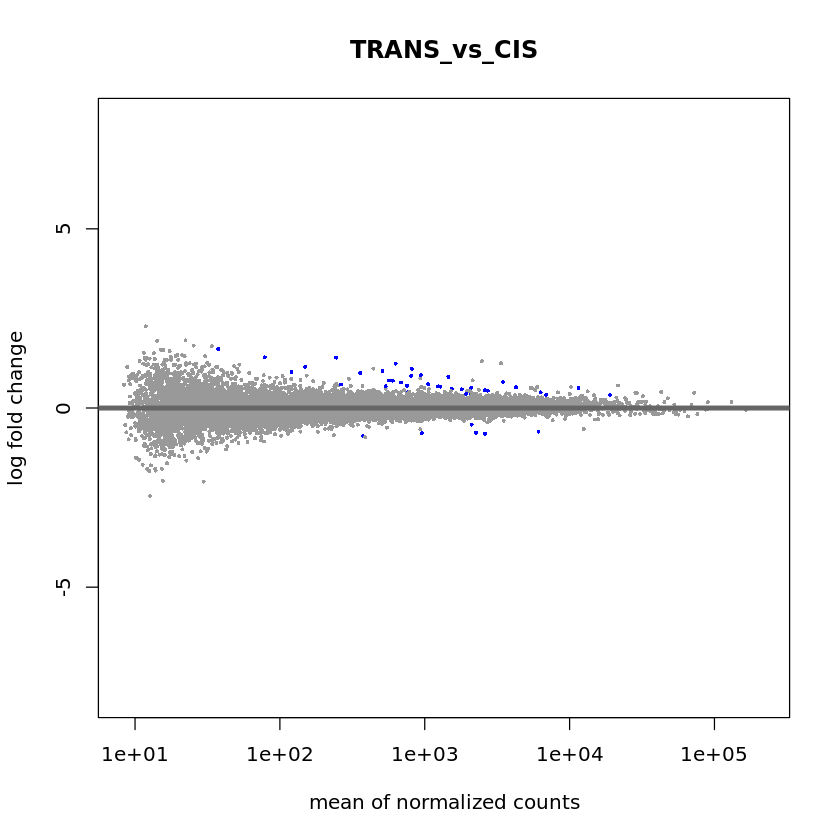

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

Significant DE genes (padj < 0.05): 41

Over-expressed genes: 35

Under-expressed genes: 6


Building most specific GOs .....

	( 11191 GO terms found. )


Build GO DAG topology ..........

	( 14548 GO terms and 32602 relations. )


Annotating nodes ...............

	( 13271 genes annotated to the GO terms. )


			 -- Weight01 Algorithm -- 

		 the algorithm is scoring 2008 nontrivial nodes
		 parameters: 
			 test statistic: fisher


	 Level 16:	3 nodes to be scored	(0 eliminated genes)


	 Level 15:	7 nodes to be scored	(0 eliminated genes)


	 Level 14:	12 nodes to be scored	(59 eliminated genes)


	 Level 13:	32 nodes to be scored	(185 eliminated genes)


	 Level 12:	70 nodes to be scored	(412 eliminated genes)


	 Level 11:	126 nodes to be scored	(966 eliminated genes)


	 Level

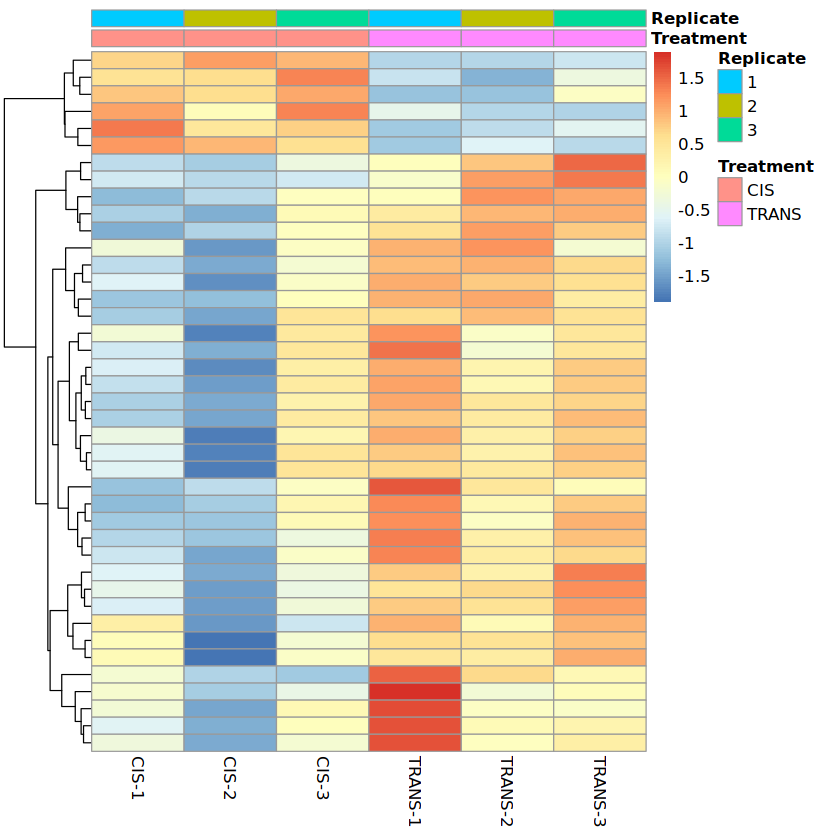

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call.graphics(C_text, as.

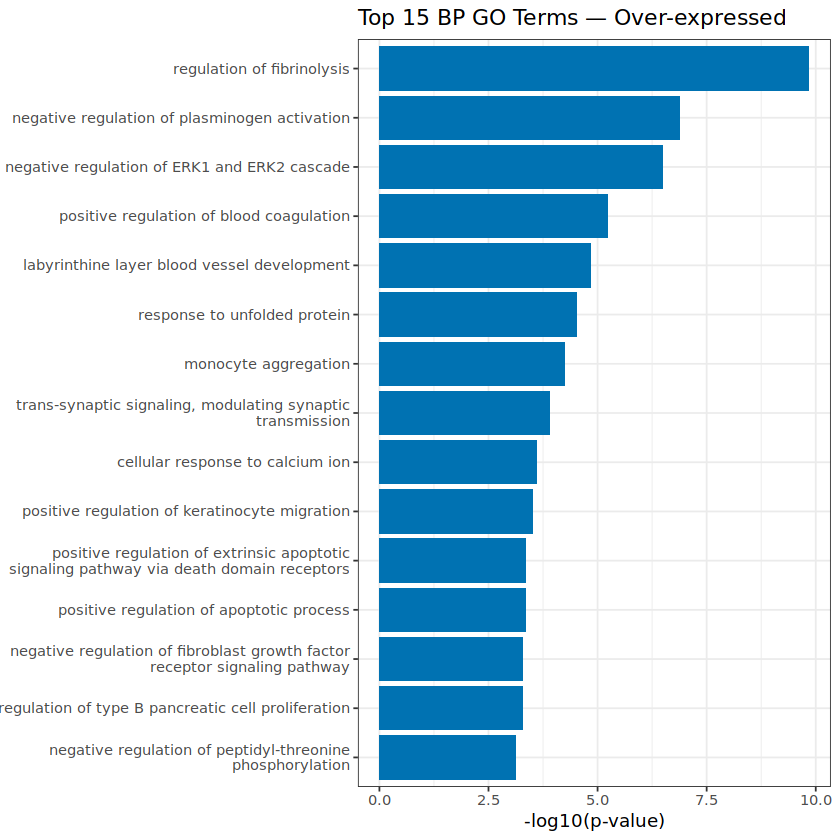

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call.graphics(C_text, as.graphicsAn

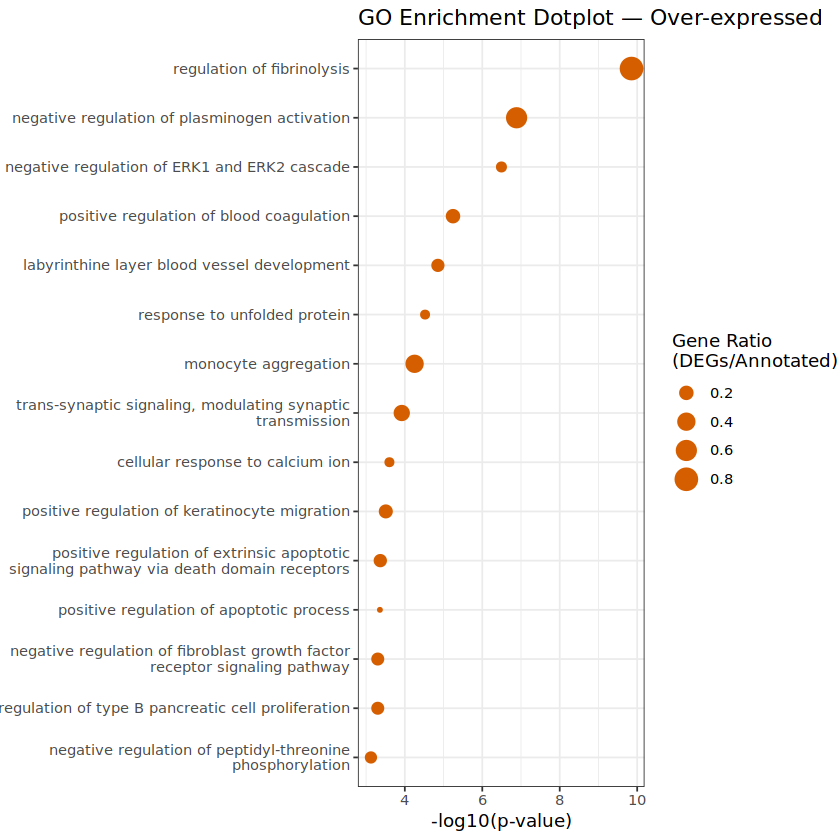

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call.graphics(C_text

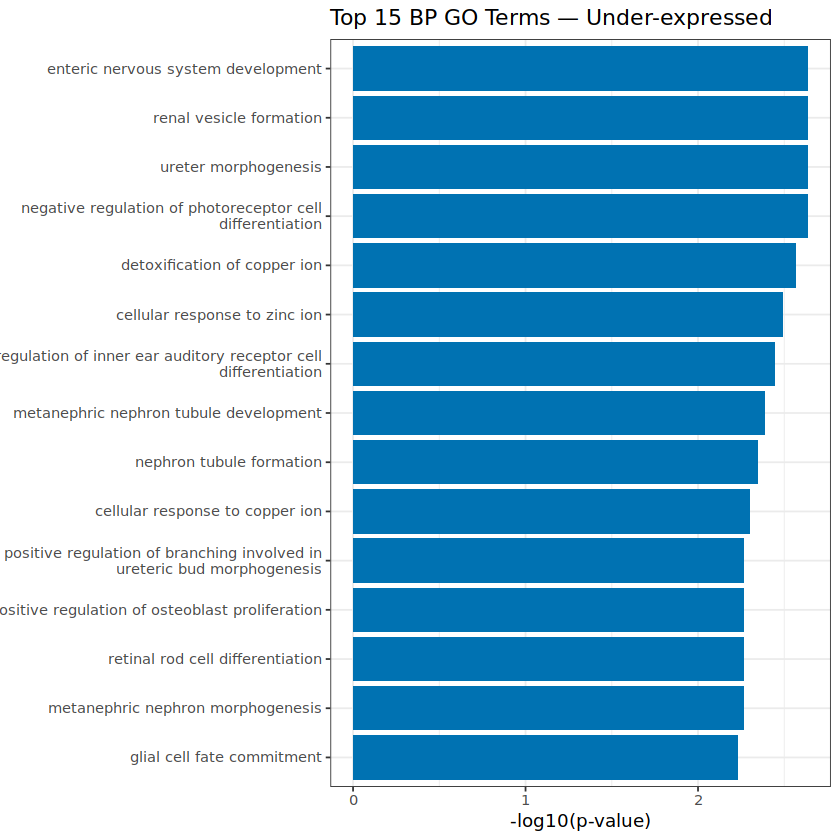

[1] "..."


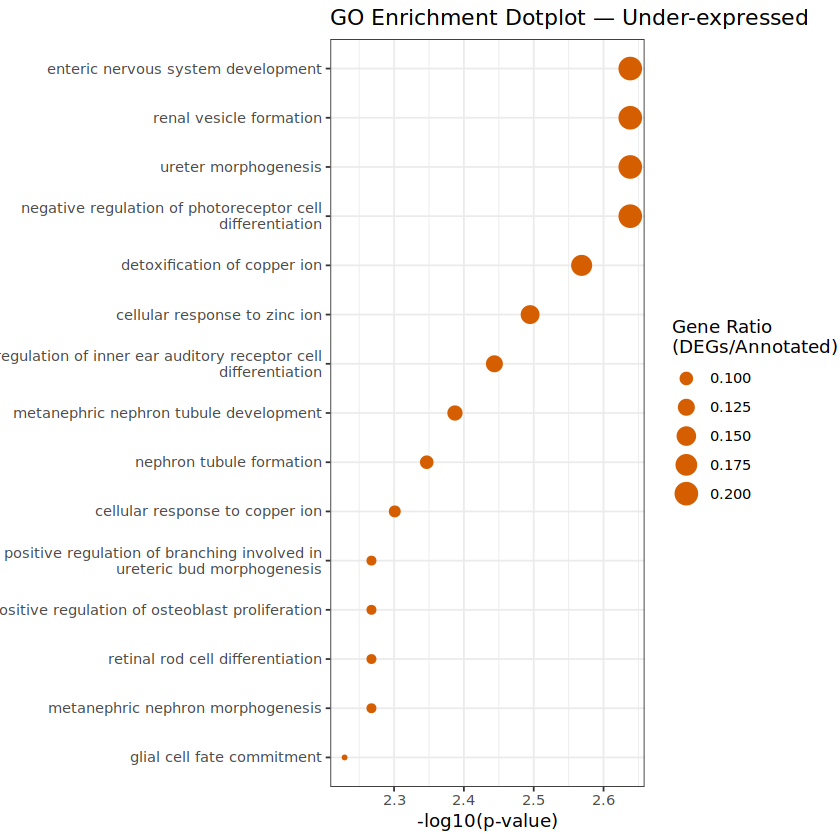

In [30]:
treatment = "TRANS"

res <- getDEresults(countsRAW, coldata, treatment)
dds <- res$dds
coldata_select <- res$coldata_select
df <- res$df

print(colSums(df))

contrast <- c("Treatment", treatment, "CIS")
sig <- getDEanalysis(dds, contrast, df, coldata_select)

if (nrow(sig) > 0) {
  sig_new <- getDEanalysisFull(dds, contrast, df, coldata_select)
  pdf(paste0("Volcano_plot_", treatment, "_vs_CIS.pdf"))
  print(sig_new$Volcanoplot)
  dev.off()
  write_xlsx(data.frame(sig_new$DEgenes_over), paste0("DEGs_", treatment, "_vs_CIS_upregulated.xlsx"))
  write_xlsx(data.frame(sig_new$DEgenes_under), paste0("DEGs_", treatment, "_vs_CIS_downregulated.xlsx"))
  print(sig_new$GOplots$over$bar)
  pdf(paste0("GOplot_over_", treatment, "_vs_CIS.pdf"))
  print(sig_new$GOplots$over$dot)
  dev.off()
  print(sig_new$GOplots$over$dot)
  print(sig_new$GOplots$under$bar)
  pdf(paste0("GOplot_under_", treatment, "_vs_CIS.pdf"))
  print(sig_new$GOplots$under$dot)
  dev.off()
  print(sig_new$GOplots$under$dot)
  write_xlsx(data.frame(sig_new$GOresults_over), paste0("GOterms_", treatment, "_vs_CIS_upregulated.xlsx"))
  write_xlsx(data.frame(sig_new$GOresults_under), paste0("GOterms_", treatment, "_vs_CIS_downregulated.xlsx"))
  print("...")
}


### Compare CIS/TRANS vs. AUF

In [31]:
# Function to subset data to dataframe (treatments of interest) for creation of DESeq object

getDEresults <- function(df, coldata, treatment) {

  # subset to tissue (cell state)
  df_select <- df[,c("AUF-1", "AUF-2", "AUF-3",
                  "CIS-1",	"CIS-2",	"CIS-3",
                  "TRANS-1",	"TRANS-2",	"TRANS-3")]

  # metadata for the selected samples
  coldata_select <- coldata[colnames(df_select), c("Treatment", "Replicate")]
  coldata_select <- dplyr::filter(coldata_select, Treatment %in% c("AUF", treatment))

  # set factor levels so DESeq2 contrast works
  coldata_select$Treatment  <- factor(coldata_select$Treatment, levels = c("AUF", treatment))
  coldata_select$Replicate  <- factor(coldata_select$Replicate)

  # reorder columns to match coldata_select row order
  df_select <- df_select[, rownames(coldata_select), drop = FALSE]

  # Gene filtering
  min_samples <- ceiling(ncol(df_select) * 0.5)
  keep <- rowSums(df_select > 10) >= min_samples
  df_select <- df_select[keep, ]

  # DESeq2
  dds <- DESeq2::DESeqDataSetFromMatrix(
    countData = round(df_select),
    colData   = coldata_select,
    design    = ~ Treatment
  )
  dds <- DESeq2::DESeq(dds)

  # return ONE object: a named list
  return(list(
    dds = dds,
    coldata_select = coldata_select,
    df = df_select
  ))
}

# Function to get results for specific contrasts (comparisons), plot MAplot and get list of DEgenes between conditions.

getDEanalysis <- function(dds, comparison, countData, coldata){
  res <- results(dds, contrast = comparison, alpha = 0.05) # significance threshold for adjusted p-value of 5 %
  plotMA(res, ylim = c(-8,8), main = paste0(comparison[2],"_vs_",comparison[3]))
  summary(res)
  print(paste0("Significant DE genes at adjusted p-value of 0.05: ", sum(res$padj < 0.05, na.rm=TRUE)))
  resOrdered <- res[order(res$padj),]
  resSig <- subset(resOrdered, padj < 0.05)
  df <- countData[rownames(resSig),order(colnames(countData))]
  anno <- coldata[colnames(df), c("Treatment", "Replicate")]
  if ((length(rownames(resSig)) < 30) & (length(rownames(resSig)) > 1)){
    pheatmap(df, cluster_cols = FALSE, scale = "row", cluster_rows = TRUE, annotation_col = anno)
  } else if (length(rownames(resSig)) >= 30) {
    pheatmap(df, cluster_cols = FALSE, scale = "row", cluster_rows = TRUE, show_rownames = FALSE, annotation_col = anno)
  }
  
  return(resSig)
}

# Function to perform a comprehensive DE and enrichment analysis 

getDEanalysisFull <- function(dds, comparison, countData, coldata, ontology = "BP", nTopGO = 15) {

  library(topGO)
  library(org.Mm.eg.db)
  library(AnnotationDbi)
  library(ggplot2)
  library(pheatmap)

  ## ──────────────────────────────────────────────
  ## Differential expression
  ## ──────────────────────────────────────────────

  res <- results(dds, contrast = comparison, alpha = 0.05)
  res_shrunk <- DESeq2::lfcShrink(dds, contrast = comparison, type = "ashr")
  res_shrunk <- res_shrunk[!is.na(res_shrunk$log2FoldChange) & abs(res_shrunk$log2FoldChange) <= 10, ]
  resOrdered <- res_shrunk[order(res_shrunk$padj), ]
  resSig <- subset(resOrdered, padj < 0.05)

  message("Significant DE genes (padj < 0.05): ", nrow(resSig))

  ## Volcano plot
  res_df <- as.data.frame(res_shrunk)
  res_df$gene <- rownames(res_df)
  res_df$neglog10padj <- -log10(res_df$padj)
  res_df$sig <- ifelse(res_df$padj < 0.05, "Significant", "Not significant")

  volcano_plot <- ggplot(res_df, aes(x = log2FoldChange, y = neglog10padj, color = sig)) +
    geom_point(alpha=0.7) +
    scale_color_manual(values = c("grey", "#D55E00")) +
    ggrepel::geom_text_repel(
      data = subset(res_df, padj < 0.05),
      aes(label = gene),
      size = 2.5,
      max.overlaps = 20,
      color = "black"
    ) +
    labs(title="Volcano Plot", x="log2 Fold Change", y="-log10(adjusted p)") +
    theme_bw() +
    xlim(-10, 10) +
    ylim(0, 12.5)

  ## ──────────────────────────────────────────────
  ## Split into over- and under-expressed sets
  ## ──────────────────────────────────────────────
  res_over  <- subset(resSig, log2FoldChange > 0)
  res_under <- subset(resSig, log2FoldChange < 0)

  message("Over-expressed genes: ", nrow(res_over))
  message("Under-expressed genes: ", nrow(res_under))

  ## Helper function to perform topGO and generate plots
  run_topGO <- function(sigGenes, universeGenes, label) {

    if (length(sigGenes) < 5) {
      message("Skipping topGO for ", label, " — not enough significant genes.")
      return(list(results=NULL, bar=NULL, dot=NULL))
    }

    geneList <- factor(as.integer(universeGenes %in% sigGenes))
    names(geneList) <- universeGenes

    geneID2GO <- annFUN.org(
      whichOnto = ontology,
      feasibleGenes = universeGenes,
      mapping = "org.Mm.eg.db",
      ID = "SYMBOL"
    )

    GOdata <- new("topGOdata",
                  ontology = ontology,
                  allGenes = geneList,
                  annot = annFUN.GO2genes,
                  GO2genes = geneID2GO,
                  nodeSize = 5)

    resultFisher <- runTest(GOdata, algorithm="weight01", statistic="fisher")

    goRes <- GenTable(GOdata,
                      Fisher = resultFisher,
                      orderBy = "Fisher",
                      topNodes = length(score(resultFisher)),
                      numChar = 1000)
    goRes$Fisher <- as.numeric(goRes$Fisher)
    goRes <- goRes[goRes$Fisher < 0.05, ]

    if (nrow(goRes) == 0) {
      message("No GO terms enriched for ", label)
      return(list(results=goRes, bar=NULL, dot=NULL))
    }

    ## Select top N
    topN <- min(nTopGO, nrow(goRes))
    goTop <- goRes[1:topN, ]
    goTop$GeneRatio <- goTop$Significant / goTop$Annotated
    goTop$Term <- make.unique(as.character(goTop$Term))
    # goTop$Term <- factor(goTop$Term, levels = rev(goTop$Term))
    # Wrap long GO term names onto multiple lines
    goTop$Term_wrapped <- str_wrap(goTop$Term, width = 50)

    # Preserve plotting order
    goTop$Term_wrapped <- factor(goTop$Term_wrapped, levels = rev(goTop$Term_wrapped))

    ## Bar plot
    barplot <- ggplot(goTop, aes(x = Term_wrapped, y = -log10(Fisher))) +
      geom_bar(stat="identity", fill="#0072B2") +
      coord_flip() +
      labs(title=paste("Top", topN, ontology, "GO Terms —", label),
           y="-log10(p-value)", x="") +
      theme_bw()

    dotplot <- ggplot(goTop, aes(x = -log10(Fisher), y = Term_wrapped, size = GeneRatio)) +
  geom_point(color = "#D55E00") +
  scale_size_continuous(name = "Gene Ratio\n(DEGs/Annotated)") +
  labs(title = paste("GO Enrichment Dotplot —", label),
       x = "-log10(p-value)", y = "") +
  theme_bw()

    return(list(results=goRes, bar=barplot, dot=dotplot))
  }

  universe <- rownames(res_shrunk)

  ## Run GO for over- and under-expressed genes
  GO_over  <- run_topGO(rownames(res_over), universe, "Over-expressed")
  GO_under <- run_topGO(rownames(res_under), universe, "Under-expressed")

  ## Return everything
  return(list(
    DEgenes_over   = res_over,
    DEgenes_under  = res_under,
    GOresults_over = GO_over$results,
    GOresults_under = GO_under$results,
    GOplots = list(
      over = list(bar = GO_over$bar, dot = GO_over$dot),
      under = list(bar = GO_under$bar, dot = GO_under$dot)
    ),
    Volcanoplot = volcano_plot
  ))
}

converting counts to integer mode



estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



   AUF-1    AUF-2    AUF-3  TRANS-1  TRANS-2  TRANS-3 
20226667 22525100 22154105 22101891 21100545 22032690 

out of 15495 with nonzero total read count
adjusted p-value < 0.05
LFC > 0 (up)       : 67, 0.43%
LFC < 0 (down)     : 45, 0.29%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 7)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results

[1] "Significant DE genes at adjusted p-value of 0.05: 112"


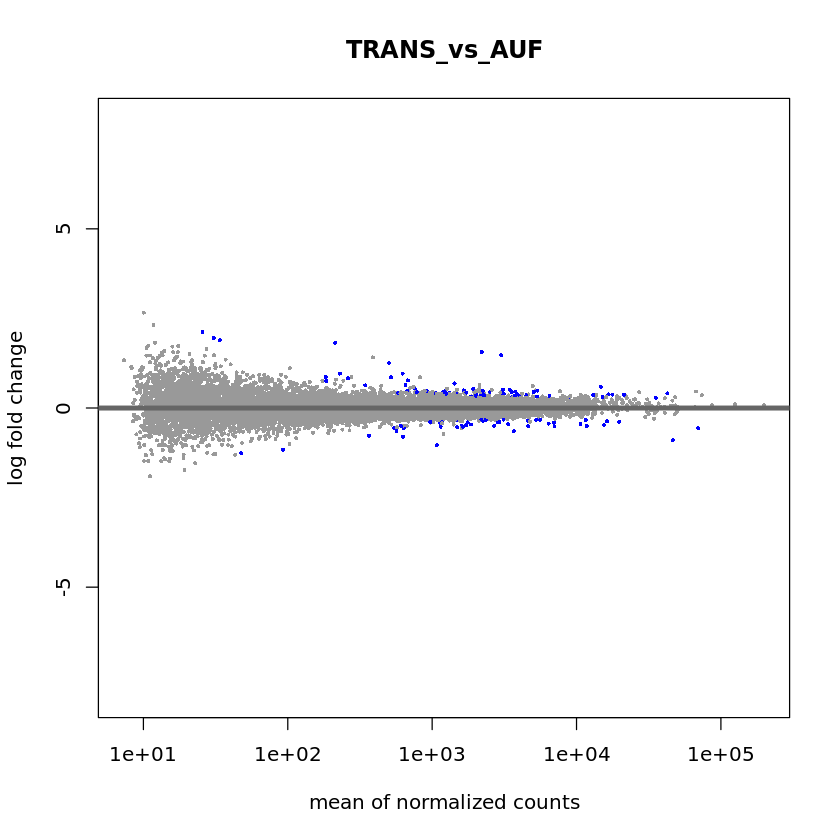

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

Significant DE genes (padj < 0.05): 114

Over-expressed genes: 68

Under-expressed genes: 46


Building most specific GOs .....

	( 11178 GO terms found. )


Build GO DAG topology ..........

	( 14541 GO terms and 32597 relations. )


Annotating nodes ...............

	( 13208 genes annotated to the GO terms. )


			 -- Weight01 Algorithm -- 

		 the algorithm is scoring 2776 nontrivial nodes
		 parameters: 
			 test statistic: fisher


	 Level 17:	3 nodes to be scored	(0 eliminated genes)


	 Level 16:	8 nodes to be scored	(0 eliminated genes)


	 Level 15:	18 nodes to be scored	(28 eliminated genes)


	 Level 14:	25 nodes to be scored	(140 eliminated genes)


	 Level 13:	47 nodes to be scored	(321 eliminated genes)


	 Level 12:	95 nodes to be scored	(661 eliminated genes)


	 Leve

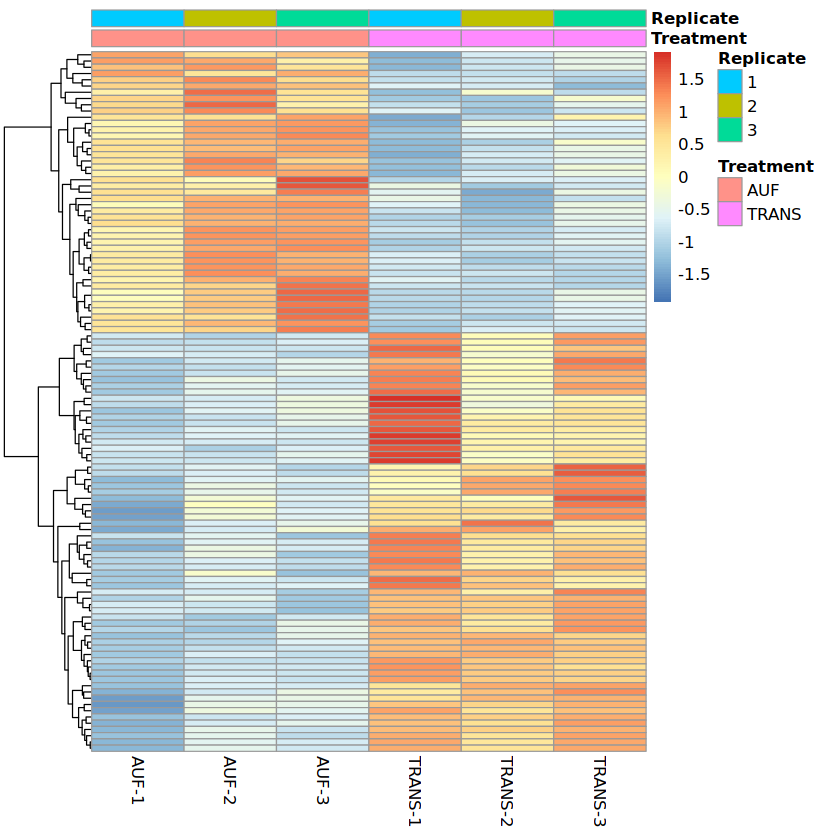

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call.graphics(C_text, as.

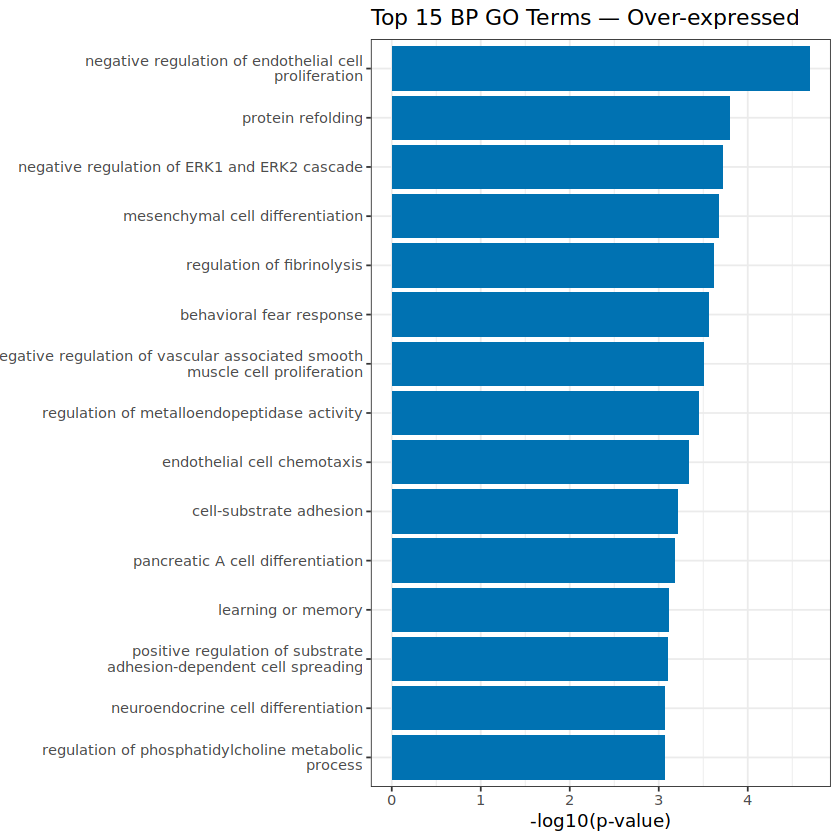

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call.graphics(C_text, as.graphicsAn

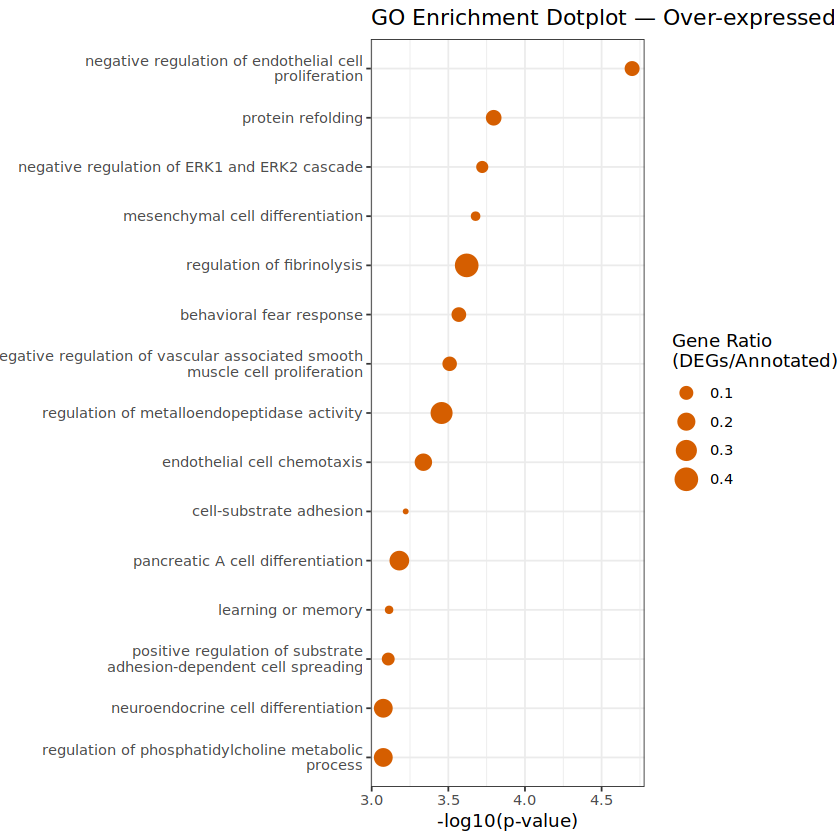

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call.graphics(C_text

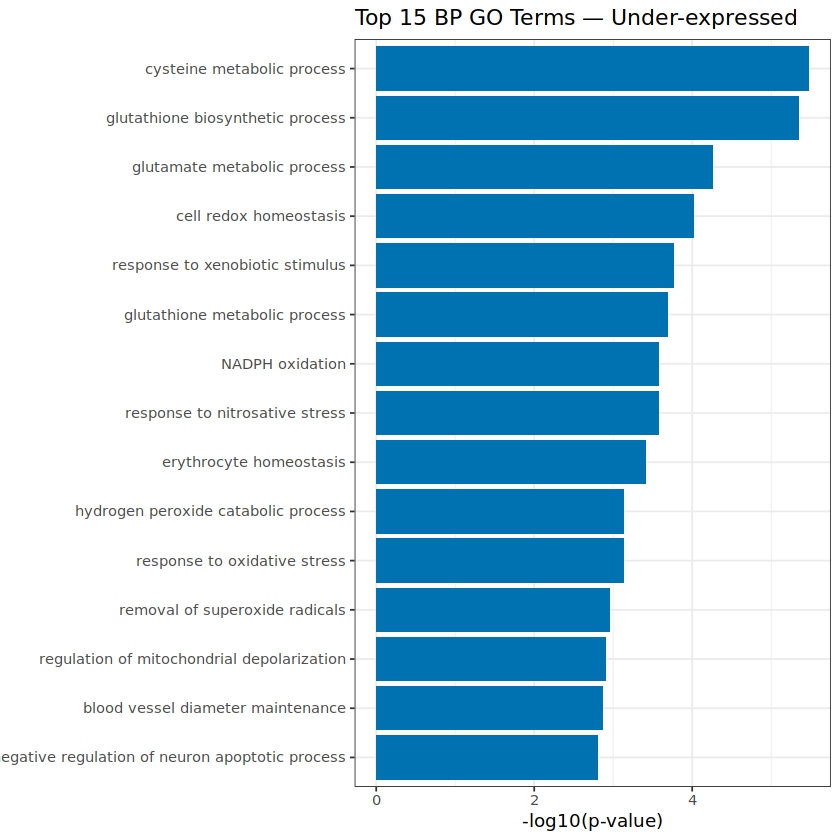

[1] "..."


converting counts to integer mode

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



   AUF-1    AUF-2    AUF-3    CIS-1    CIS-2    CIS-3 
20227270 22525909 22154614 26044774 22307387 25856697 


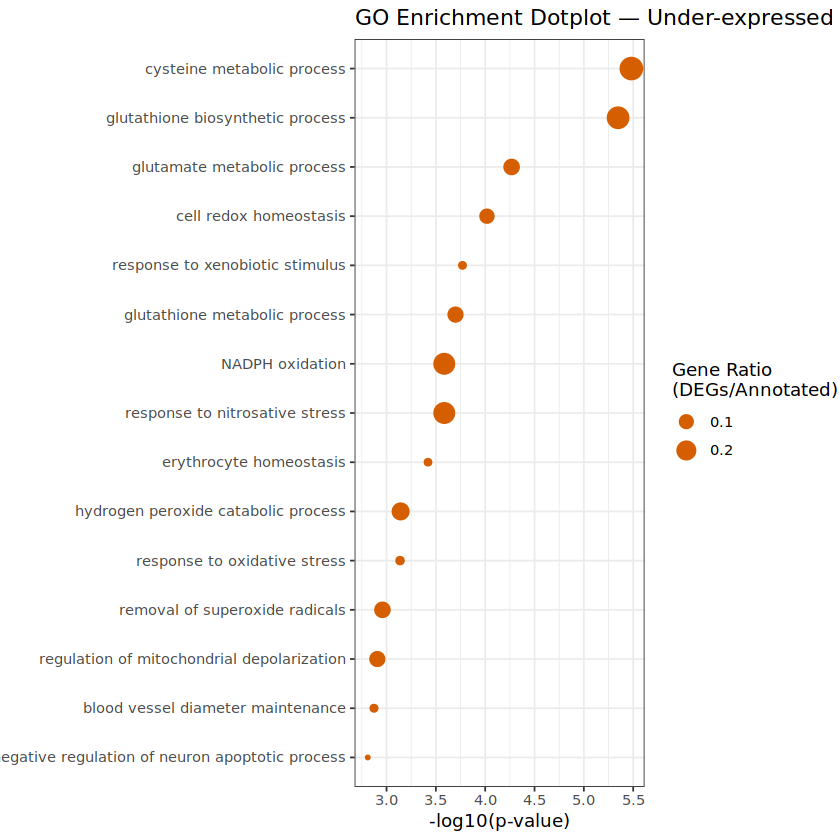


out of 15561 with nonzero total read count
adjusted p-value < 0.05
LFC > 0 (up)       : 50, 0.32%
LFC < 0 (down)     : 81, 0.52%
outliers [1]       : 0, 0%
low counts [2]     : 3017, 19%
(mean count < 72)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results

[1] "Significant DE genes at adjusted p-value of 0.05: 131"


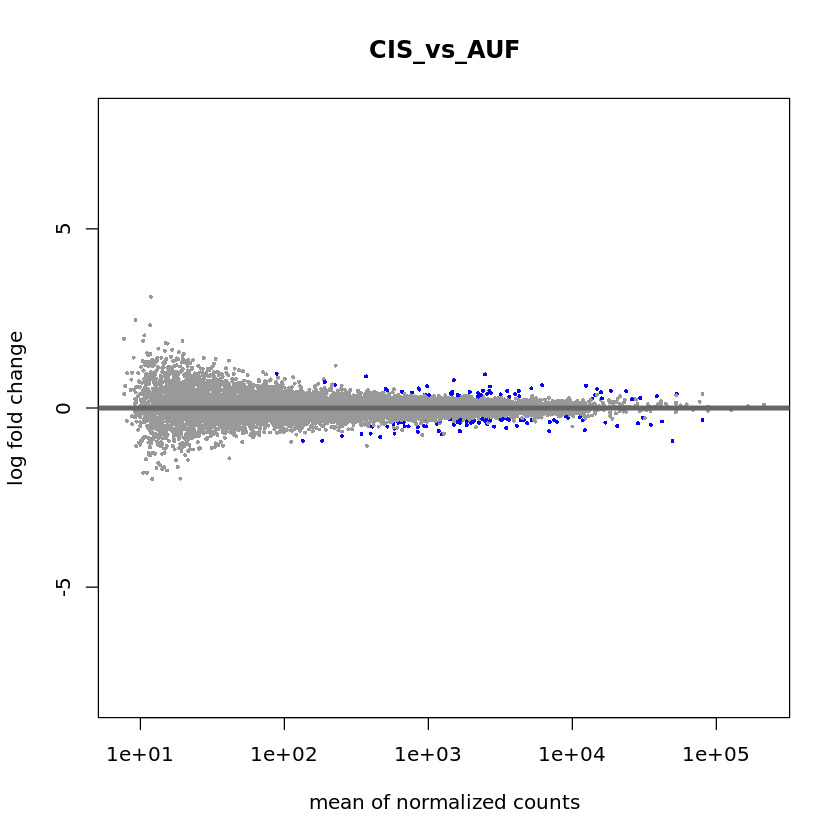

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

Significant DE genes (padj < 0.05): 129

Over-expressed genes: 49

Under-expressed genes: 80


Building most specific GOs .....

	( 11189 GO terms found. )


Build GO DAG topology ..........

	( 14549 GO terms and 32616 relations. )


Annotating nodes ...............

	( 13252 genes annotated to the GO terms. )


			 -- Weight01 Algorithm -- 

		 the algorithm is scoring 1577 nontrivial nodes
		 parameters: 
			 test statistic: fisher


	 Level 16:	3 nodes to be scored	(0 eliminated genes)


	 Level 15:	5 nodes to be scored	(0 eliminated genes)


	 Level 14:	10 nodes to be scored	(23 eliminated genes)


	 Level 13:	21 nodes to be scored	(166 eliminated genes)


	 Level 12:	51 nodes to be scored	(482 eliminated genes)


	 Level 11:	91 nodes to be scored	(906 eliminated genes)


	 Leve

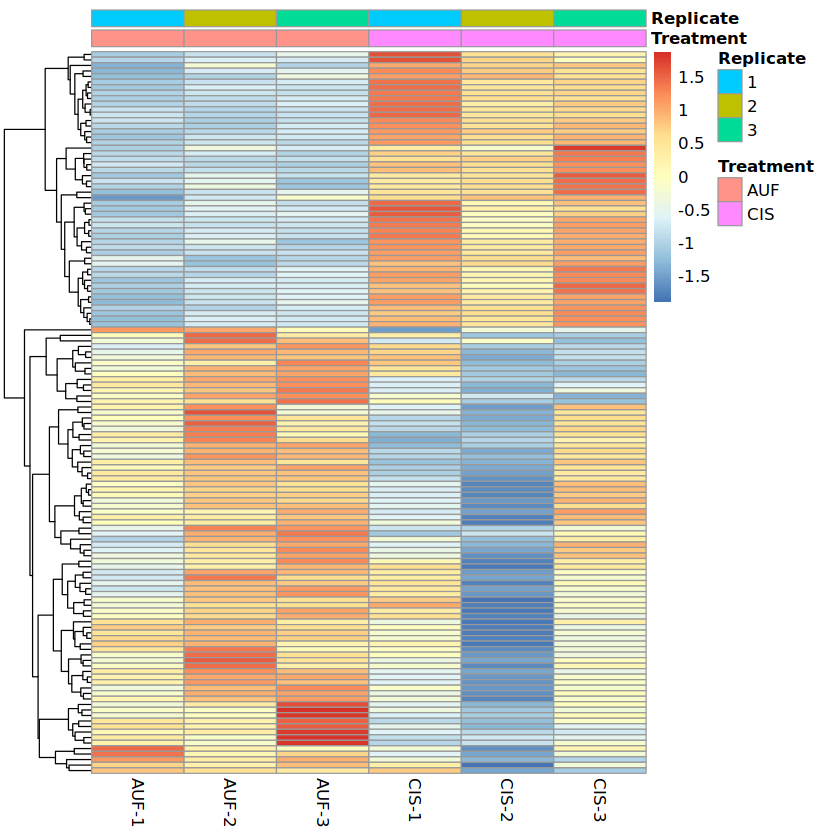

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Over-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call.graphics(C_text, as.

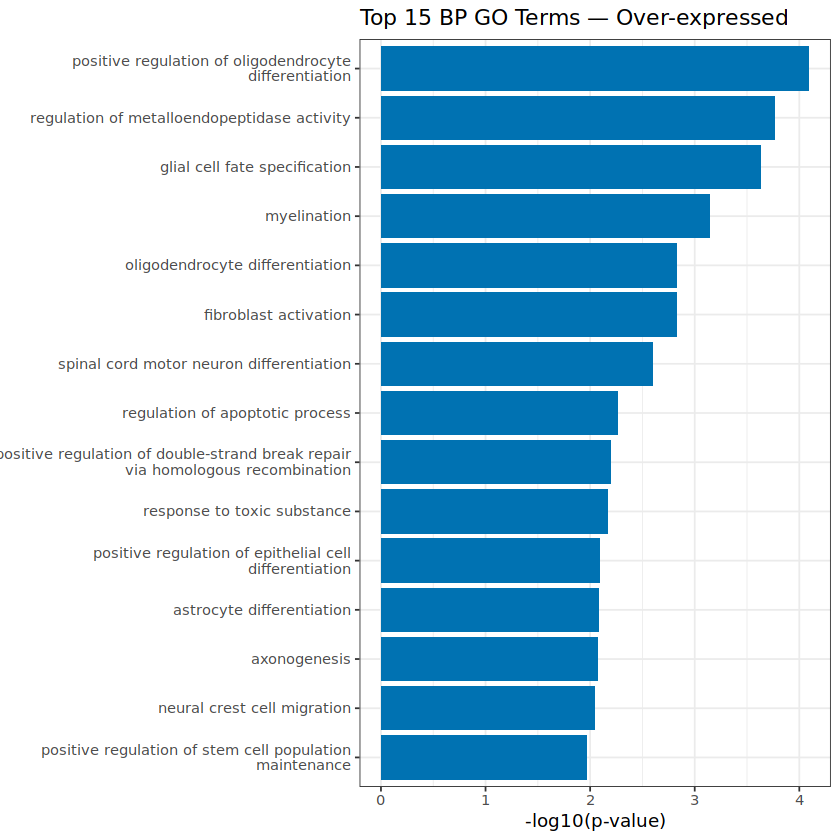

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Top 15 BP GO Terms — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call.graphics(C_text, as.graphicsAn

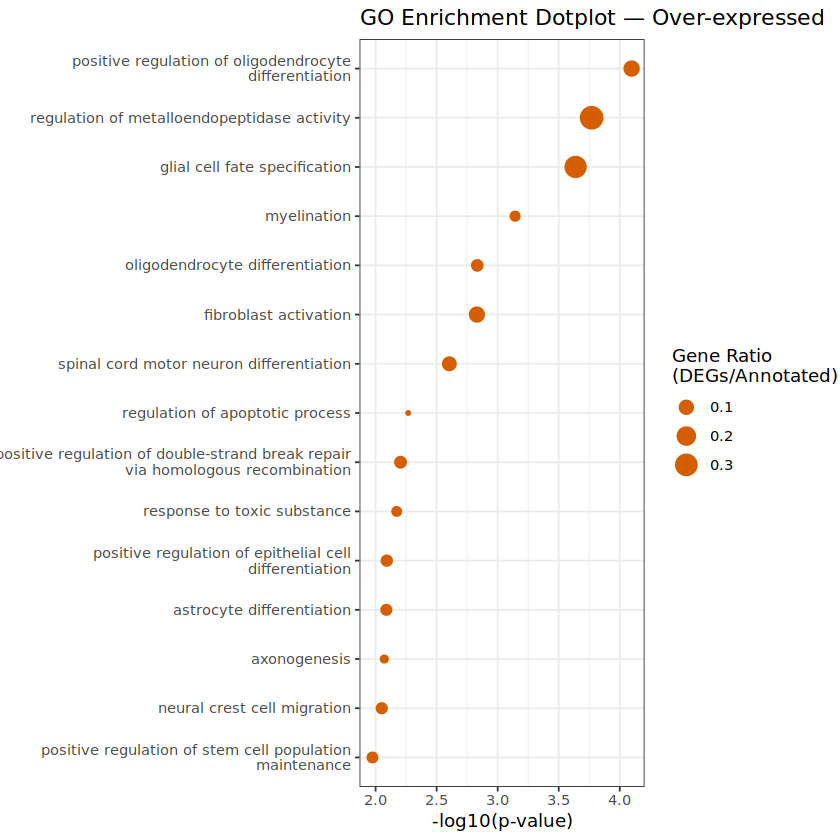

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <94>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'GO Enrichment Dotplot — Under-expressed' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call.graphics(C_text

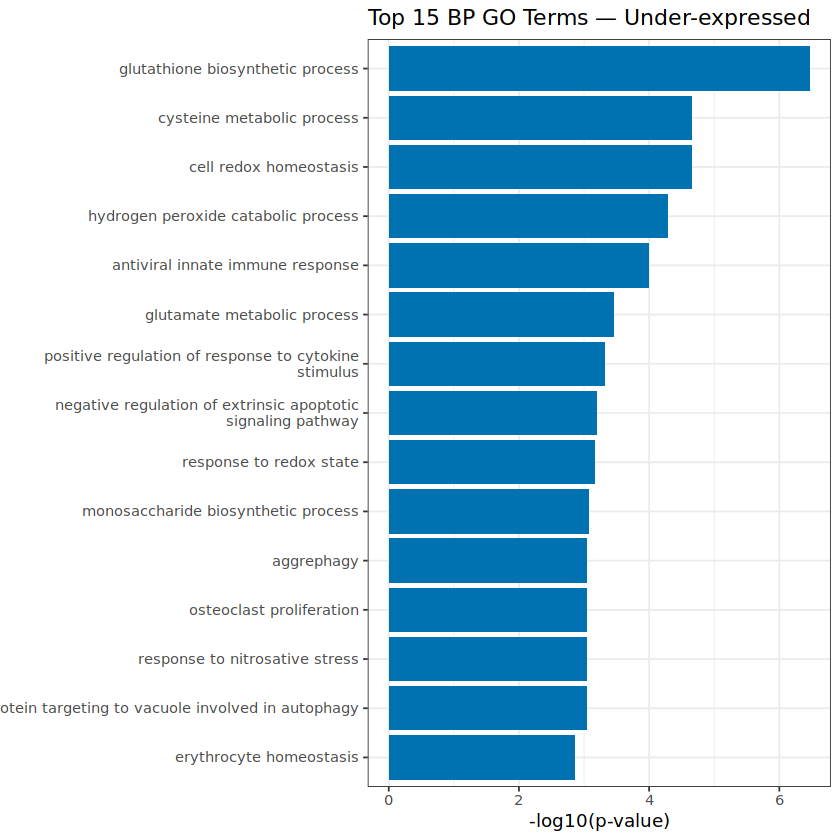

[1] "..."


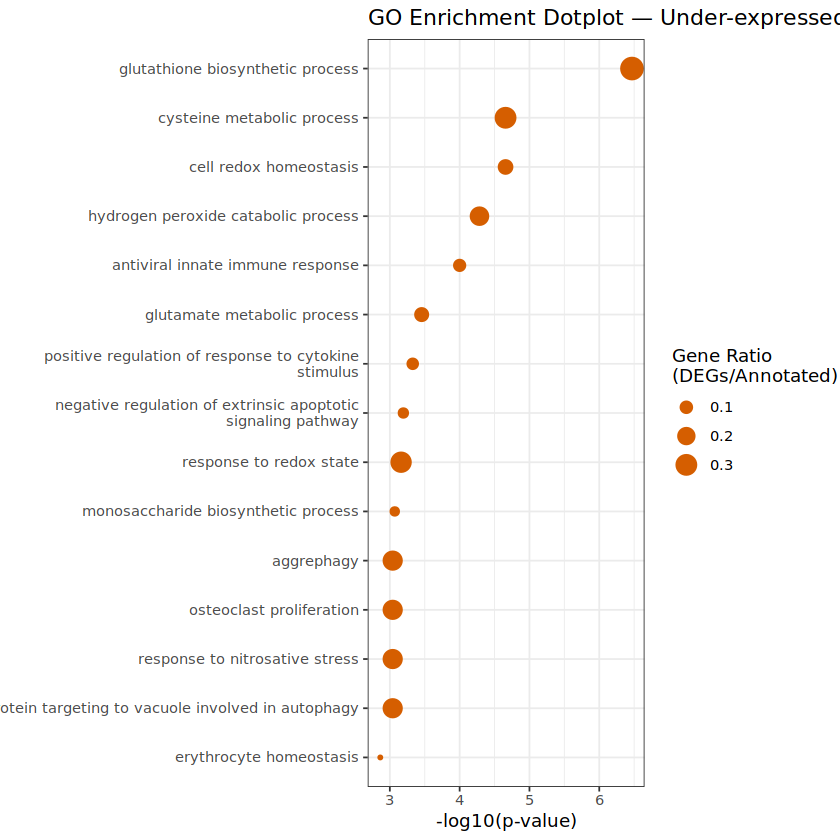

In [32]:
for (treatment in c("TRANS", "CIS")){

    res <- getDEresults(countsRAW, coldata, treatment)
    dds <- res$dds
    coldata_select <- res$coldata_select
    df <- res$df

    print(colSums(df))

    contrast <- c("Treatment", treatment, "AUF")
    sig <- getDEanalysis(dds, contrast, df, coldata_select)

    if (nrow(sig) > 0) {
    sig_new <- getDEanalysisFull(dds, contrast, df, coldata_select)
    pdf(paste0("Volcano_plot_", treatment, "_vs_AUF.pdf"))
    print(sig_new$Volcanoplot)
    dev.off()
    write_xlsx(data.frame(sig_new$DEgenes_over), paste0("DEGs_", treatment, "_vs_AUF_upregulated.xlsx"))
    write_xlsx(data.frame(sig_new$DEgenes_under), paste0("DEGs_", treatment, "_vs_AUF_downregulated.xlsx"))
    print(sig_new$GOplots$over$bar)
    pdf(paste0("GOplot_over_", treatment, "_vs_AUF.pdf"))
    print(sig_new$GOplots$over$dot)
    dev.off()
    print(sig_new$GOplots$over$dot)
    print(sig_new$GOplots$under$bar)
    pdf(paste0("GOplot_under_", treatment, "_vs_AUF.pdf"))
    print(sig_new$GOplots$under$dot)
    dev.off()
    print(sig_new$GOplots$under$dot)
    write_xlsx(data.frame(sig_new$GOresults_over), paste0("GOterms_", treatment, "_vs_AUF_upregulated.xlsx"))
    write_xlsx(data.frame(sig_new$GOresults_under), paste0("GOterms_", treatment, "_vs_AUF_downregulated.xlsx"))
    print("...")
    }
}